In [ ]:
import itertools, time, re, json, warnings, atexit
from pathlib import Path
from itertools import combinations, product
from contextlib import ExitStack
from types import MethodType
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as student_t
from IPython.display import display
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile as _qiskit_transpile
from qiskit.circuit import Gate, Measure
from qiskit.circuit.library import XGate, YGate
from qiskit.quantum_info import Statevector, DensityMatrix, Operator, Pauli, state_fidelity, partial_trace
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDynamicalDecoupling
from qiskit_ibm_runtime import QiskitRuntimeService, Batch, SamplerV2 as Sampler
from qiskit_ibm_runtime.circuit import MidCircuitMeasure
from qiskit_aer import AerSimulator
from qiskit_experiments.framework import ExperimentData
from qiskit_experiments.library import StateTomography as _BASE_STATE_TOMO, MitigatedStateTomography as _BASE_MITIGATED_TOMO
from datetime import datetime as _progress_datetime
from time import monotonic as _progress_clock
from functools import wraps as _progress_wraps
from inspect import signature as _progress_signature
MEASUREMENT_SCHEME = 'MCM'
ARTIFACT_OUTPUT_DIR = Path.cwd() / 'ame52_mcm_rank1_v044_batch'
HARDWARE_CALIBRATION_HISTORY_PATH = Path.cwd() / 'hardware_calibration_history.txt'  # shared across all four notebooks; append-only
ARTIFACT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
N_TRIALS = 1
TOMOGRAPHY_SHOTS = 5000
WITNESS_SHOTS = 5000
SWAP_SHOTS = 5000
M3_CALIBRATION_SHOTS = 5000
DD_POLICIES = ('No DD', 'XY4')
# XX DD is intentionally excluded from submission, CSVs, and plots.
HARDWARE_BACKEND_NAME = 'ibm_pittsburgh'
ACTIVE_APPLY_DD = False
ACTIVE_DD_SEQUENCE = 'XY4'
_HARDWARE_BATCH_STACK = None
_HARDWARE_BATCHES = {}
_HARDWARE_BATCH_CLEANUP_REGISTERED = False
_DD_PROGRESS_CONTEXT = 'setup'
AME52_MAINTENANCE_POLL_SECONDS = 600
AME52_JOB_MAX_ATTEMPTS = 5
AME52_JOB_RETRY_BASE_SECONDS = 30
AUTOMATIC_BACKEND_SELECTION_ENABLED = False
BACKEND_SELECTION_PRIMARY = 'qerror'
BACKEND_SELECTION_SECONDARY = 'readout_error'
_X = np.array([[0, 1], [1, 0]], dtype=complex)
_Z = np.array([[1, 0], [0, -1]], dtype=complex)
Z_99 = 2.5758293035489004
PHI_PLUS_SV = Statevector(np.array([1, 0, 0, 1], dtype=complex) / np.sqrt(2))
psi_A = np.array([1, 1], dtype=complex) / np.sqrt(2)
phi_B = np.array([1, -1], dtype=complex) / np.sqrt(2)
_T99_TABLE = {1: 63.657, 2: 9.925, 3: 5.841, 4: 4.604, 5: 4.032, 6: 3.707, 7: 3.499, 8: 3.355, 9: 3.25, 10: 3.169, 11: 3.106, 12: 3.055, 13: 3.012, 14: 2.977, 15: 2.947, 16: 2.921, 17: 2.898, 18: 2.878, 19: 2.861, 20: 2.845, 21: 2.831, 22: 2.819, 23: 2.807, 24: 2.797, 25: 2.787, 26: 2.779, 27: 2.771, 28: 2.763, 29: 2.756, 30: 2.75}

# Synthesized rank-1 decoder and channel assignment.
DISENTANGLER_RANK = 1
RANK_ACTIVE_AME_QUBITS = (0, 1, 4)
RANK_SOURCE_A = 2
RANK_RECEIVER_A = 0
RANK_SOURCE_B = 3
RANK_RECEIVER_B = 1
ACTIVE_DD_POLICIES = ('No DD', 'XY4')



In [ ]:

def _swap_readout_qubits(circuit, register_name):
    registers = [r for r in circuit.cregs if r.name == register_name]
    if len(registers) != 1 or len(registers[0]) != 1:
        raise RuntimeError(f'Expected one-bit SWAP register {register_name!r}.')
    bit = registers[0][0]
    reads = [i for i in circuit.data if i.operation.name in ('measure', 'measure_2') and bit in i.clbits]
    if len(reads) != 1:
        raise RuntimeError(f'Expected one measurement into {register_name}; found {len(reads)}.')
    return [circuit.find_bit(reads[0].qubits[0]).index]

def _swap_ideal_scheduled_p0(circuit, register_name, max_active=18):
    """Exact local check of static scheduled circuits; never submit a job."""
    from qiskit.quantum_info import Statevector
    readout = _swap_readout_qubits(circuit, register_name)[0]
    ignored = {'measure', 'measure_2', 'barrier', 'delay'}
    operations = [i for i in circuit.data if i.operation.name not in ignored]
    if any((getattr(i.operation, 'blocks', ()) or i.operation.name == 'reset' for i in operations)):
        return None
    active = sorted({readout} | {circuit.find_bit(q).index for i in operations for q in i.qubits})
    if len(active) > max_active:
        return None
    indices = {q: j for j, q in enumerate(active)}
    compact = QuantumCircuit(len(active))
    for i in operations:
        compact.append(i.operation, [indices[circuit.find_bit(q).index] for q in i.qubits])
    return float(Statevector.from_instruction(compact).probabilities([indices[readout]])[0])

def close_hardware_batches(_result=None):
    """Close this cell's Runtime batches and release dedicated access."""
    global _HARDWARE_BATCH_STACK
    global _HARDWARE_BATCHES
    global _HARDWARE_BATCH_CLEANUP_REGISTERED
    stack = _HARDWARE_BATCH_STACK
    _HARDWARE_BATCH_STACK = None
    _HARDWARE_BATCHES = {}
    close_error = None
    if stack is not None:
        try:
            stack.close()
        except Exception as exc:
            close_error = exc
    if _HARDWARE_BATCH_CLEANUP_REGISTERED:
        try:
            shell = get_ipython()
            if shell is not None:
                shell.events.unregister('post_run_cell', close_hardware_batches)
        except (NameError, ValueError):
            pass
        _HARDWARE_BATCH_CLEANUP_REGISTERED = False
    if close_error is not None:
        raise close_error

def make_hardware_session_sampler(backend):
    """Return SamplerV2 in a shared, cell-scoped Runtime Batch.

    Note: despite the name (kept for call-site compatibility), this now
    opens a Batch rather than a Session. Batch mode is not subject to the
    interactive-TTL teardown that closes idle Sessions, which matters for
    this pipeline's stages where post-processing (M3 calibration, audit
    writes, tomography reconstruction) can exceed the 60s interactive TTL
    between job submissions.
    """
    global _HARDWARE_BATCH_STACK
    global _HARDWARE_BATCH_CLEANUP_REGISTERED
    if _HARDWARE_BATCH_STACK is None:
        _HARDWARE_BATCH_STACK = ExitStack()
        try:
            shell = get_ipython()
        except NameError:
            shell = None
        if shell is not None:
            shell.events.register('post_run_cell', close_hardware_batches)
            _HARDWARE_BATCH_CLEANUP_REGISTERED = True
        else:
            atexit.register(close_hardware_batches)
    backend_name = getattr(backend, 'name', str(backend))
    if callable(backend_name):
        backend_name = backend_name()
    if backend_name not in _HARDWARE_BATCHES:
        _HARDWARE_BATCHES[backend_name] = _HARDWARE_BATCH_STACK.enter_context(Batch(backend=backend))
        print(f'IBM Runtime Batch opened on {backend_name}; it will close when this execution cell finishes.', flush=True)
    batch = _HARDWARE_BATCHES[backend_name]
    sampler = Sampler(mode=batch)
    sampler.options.dynamical_decoupling.enable = False
    sampler.options.execution.init_qubits = True
    return sampler

def _is_simulator_backend(backend):
    """Return True for Aer/local simulator backends."""
    try:
        return bool(backend.configuration().simulator)
    except Exception:
        type_name = f'{type(backend).__module__}.{type(backend).__name__}'.lower()
        return 'aer' in type_name or 'simulator' in type_name

def _backend_instruction_names(backend):
    """Collect BackendV2 and IBM Runtime instruction-name views."""
    names = set(getattr(backend, 'operation_names', ()) or ())
    try:
        names.update(getattr(backend, 'supported_instructions', ()) or ())
    except Exception:
        pass
    target = getattr(backend, 'target', None)
    if target is not None:
        names.update(getattr(target, 'operation_names', ()) or ())
    return names

def _validate_mid_circuit_measure_backend(backend):
    """Require IBM measure_2 support before a real-hardware submission."""
    if _is_simulator_backend(backend):
        return
    if 'measure_2' not in _backend_instruction_names(backend):
        raise RuntimeError(f"Backend {getattr(backend, 'name', backend)!r} does not report measure_2 support. Choose a backend returned by service.backends(filters=lambda b: 'measure_2' in b.supported_instructions).")

def _circuit_for_backend(circuit, backend):
    return _rewrite_readouts(circuit, _readout_is_simulator(backend))

def _csv_path_for_plot(save_path, csv_path=None):
    """Return the explicit CSV path or replace the plot suffix with .csv."""
    path = Path(csv_path) if csv_path is not None else Path(save_path).with_suffix('.csv')
    path.parent.mkdir(parents=True, exist_ok=True)
    return path

def _save_plot_rows(rows, save_path, csv_path=None):
    """Save tidy source data beside a plot and return its path."""
    path = _csv_path_for_plot(save_path, csv_path)
    pd.DataFrame(rows).to_csv(path, index=False)
    print(f'  Saved CSV: {path}')
    return path

def _transpile_stage_with_dd(circuits, backend, initial_layout=None, optimization_level=3, apply_dd=True, dd_sequence='XY4', allow_unmeasured=False, routing_method=None, scheduling_scope='complete_stage_circuit'):
    """Schedule each complete stage/quantifier circuit using the EPR workflow."""
    single = isinstance(circuits, QuantumCircuit)
    inputs = [circuits] if single else list(circuits)
    policy = dd_sequence if apply_dd else 'none'
    routing_options = {} if routing_method is None else {'routing_method': routing_method}
    routed = transpile(inputs, backend, initial_layout=initial_layout, optimization_level=optimization_level, seed_transpiler=41, **routing_options)
    finals, rows = ([], [])
    for index, before in enumerate(routed):
        simulator = _readout_is_simulator(backend)
        if simulator:
            before = _rewrite_readouts(before, simulator=False)
        active = sorted({before.find_bit(q).index for i in before.data if i.operation.name != 'barrier' for q in i.qubits})
        schedule, translate, alignment = _stage_scheduling_pipeline(backend, policy, active)
        delayed = schedule.run(_unique_control_flow_bits(before))
        padded, stats = (delayed, {'dd_cycles': 0}) if policy == 'none' else _stage_insert_dd(delayed, backend, active, alignment, policy)
        x_added = int(padded.count_ops().get('x', 0) - delayed.count_ops().get('x', 0))
        y_added = int(padded.count_ops().get('y', 0) - delayed.count_ops().get('y', 0))
        cycles = int(stats['dd_cycles'])
        expected = {'none': (0, 0), 'XX': (2 * cycles, 0), 'XY4': (2 * cycles, 2 * cycles)}[policy]
        if (x_added, y_added) != expected:
            raise RuntimeError('DD cycle/pulse count audit failed.')
        final = translate.run(padded) if translate is not None else padded
        final._layout = before.layout
        _validate_physical_readouts(final, backend)
        if _readout_map(before, allow_unmeasured=allow_unmeasured) != _readout_map(final, allow_unmeasured=allow_unmeasured):
            raise RuntimeError('Scheduling changed the readout mapping.')
        if _stage_structure(before) != _stage_structure(final):
            raise RuntimeError('Scheduling changed measurements or conditional corrections.')
        if simulator:
            final = _rewrite_readouts(final, simulator=True)
        assert_terminal_measurements_are_final(final, 'full-stage schedule')
        status = 'disabled' if policy == 'none' else 'inserted' if cycles else 'no_eligible_idle_window'
        rows.append(dict(context=_DD_PROGRESS_CONTEXT, circuit=before.name, circuit_index=index, backend=str(backend.name), policy=policy, scheduling_scope=scheduling_scope, dd_cycles=cycles, inserted_x=x_added, inserted_y=y_added, dd_status=status, measured_physical=_readout_map(final, allow_unmeasured=allow_unmeasured), skipped_delays_after_measure_2=int(stats.get('skipped_delays_after_measure_2', 0)), skipped_delays_after_terminal_measure=int(stats.get('skipped_delays_after_terminal_measure', 0))))
        final.metadata = dict(final.metadata or {}, stage_dd_audit=rows[-1])
        finals.append(final)
    path = _json_audit('stage_schedule', dict(circuits=rows))
    csv_path = ARTIFACT_OUTPUT_DIR / 'stage_scheduling_audit.csv'
    pd.DataFrame(rows).to_csv(csv_path, mode='a', header=not csv_path.exists(), index=False)
    #print(f"[{_DD_PROGRESS_CONTEXT}] Full-stage scheduling: {len(rows)} circuits, DD={policy}, {sum((r['dd_cycles'] for r in rows))} cycles. Audit: {path}", flush=True)
    return finals[0] if single else finals

def _measurement_boundary_indices(circuit):
    return [i for i, item in enumerate(circuit.data)
            if item.operation.name == 'barrier'
            and item.operation.label == 'fixed_preparation_end']


def _tomography_circuits_with_boundary(self):
    """Mark the target/basis boundary before any transpiler sees the circuit."""
    if self._prep_circ_basis is not None:
        raise ValueError('Fixed-preparation compilation supports state tomography only.')
    circuits = _BASE_STATE_TOMO.circuits(self)
    boundary = len(self._circuit.data)
    marked = []
    for circuit in circuits:
        if list(circuit.data[:boundary]) != list(self._circuit.data):
            raise RuntimeError('Tomography preparation boundary could not be verified.')
        result = circuit.copy_empty_like()
        for item in circuit.data[:boundary]:
            result.append(item.operation, item.qubits, item.clbits)
        result.barrier(*result.qubits, label='fixed_preparation_end')
        for item in circuit.data[boundary:]:
            result.append(item.operation, item.qubits, item.clbits)
        marked.append(result)
    return marked


def _mitigated_tomography_circuits_with_boundary(self):
    """Keep the library's batch metadata and mark its tomography component."""
    tomography = self.component_experiment(1)
    tomography.circuits = MethodType(_tomography_circuits_with_boundary, tomography)
    return _BASE_MITIGATED_TOMO.circuits(self)


def transpile_with_dd(circuits, backend, initial_layout=None, optimization_level=3,
                      apply_dd=True, dd_sequence='XY4', calibration_follows_preparation=False):
    """Freeze preparation/DD, then attach separately compiled measurement bases."""
    single = isinstance(circuits, QuantumCircuit)
    inputs = [circuits] if single else list(circuits)
    if not any(_measurement_boundary_indices(circuit) for circuit in inputs):
        return _transpile_stage_with_dd(
            circuits, backend, initial_layout=initial_layout,
            optimization_level=optimization_level, apply_dd=apply_dd, dd_sequence=dd_sequence)

    groups, assignments = [], {}
    for index, circuit in enumerate(inputs):
        boundaries = _measurement_boundary_indices(circuit)
        if not boundaries:
            continue
        if len(boundaries) != 1:
            raise ValueError('Expected exactly one preparation/measurement boundary.')
        boundary = boundaries[0]
        preparation = circuit.copy_empty_like()
        preparation.name = 'fixed_preparation'
        preparation.metadata = {}
        for item in circuit.data[:boundary + 1]:
            preparation.append(item.operation, item.qubits, item.clbits)
        group_index = next((i for i, group in enumerate(groups)
                            if preparation == group['logical']), None)
        if group_index is None:
            fixed = _transpile_stage_with_dd(
                preparation, backend, initial_layout=initial_layout,
                optimization_level=optimization_level, apply_dd=apply_dd,
                dd_sequence=dd_sequence, allow_unmeasured=True,
                scheduling_scope='preparation_before_measurement_basis')
            if fixed.layout is None:
                raise RuntimeError('Preparation transpilation did not return its final layout.')
            logical_to_physical = list(fixed.layout.final_index_layout(filter_ancillas=True))
            if len(logical_to_physical) != preparation.num_qubits:
                raise RuntimeError('Preparation output mapping has the wrong width.')
            if len(_measurement_boundary_indices(fixed)) != 1:
                raise RuntimeError('Compilation lost the preparation/measurement boundary.')
            group_index = len(groups)
            groups.append(dict(logical=preparation, fixed=fixed, mapping=logical_to_physical))
        assignments[index] = (group_index, boundary)

    if calibration_follows_preparation and len(groups) != 1:
        raise ValueError('Mitigated tomography requires one shared preparation mapping.')
    finals, audit_rows = [], []
    for index, circuit in enumerate(inputs):
        if index not in assignments:
            # MST assignment matrices must follow the same logical states as tomography.
            layout = groups[0]['mapping'] if calibration_follows_preparation else initial_layout
            final = _transpile_stage_with_dd(
                circuit, backend, initial_layout=layout,
                optimization_level=optimization_level, apply_dd=apply_dd,
                dd_sequence=dd_sequence,
                routing_method='none' if calibration_follows_preparation else None)
            finals.append(final)
            continue
        group_index, boundary = assignments[index]
        group = groups[group_index]
        fixed, mapping = group['fixed'], group['mapping']
        # The suffix is expressed directly on physical wires. Only this suffix
        # is transpiled/scheduled; the frozen preparation is never passed back in.
        suffix = fixed.copy_empty_like()
        suffix._layout = None
        suffix.global_phase = 0
        suffix.metadata = {}
        suffix.name = circuit.name + '_measurement_basis'
        for item in circuit.data[boundary + 1:]:
            suffix.append(item.operation,
                          [suffix.qubits[mapping[circuit.find_bit(q).index]] for q in item.qubits],
                          [suffix.clbits[circuit.find_bit(c).index] for c in item.clbits])
        suffix = _transpile_stage_with_dd(
            suffix, backend, initial_layout=list(range(suffix.num_qubits)),
            optimization_level=optimization_level, apply_dd=False, dd_sequence=dd_sequence,
            allow_unmeasured=True, routing_method='none',
            scheduling_scope='measurement_basis_no_dd')
        if any(item.operation.name != 'barrier' and
               (len(item.qubits) != 1 or getattr(item.operation, 'blocks', ()))
               for item in suffix.data):
            raise ValueError('Measurement suffix must contain only single-qubit operations/readouts.')
        if suffix.layout.final_index_layout(filter_ancillas=True) != list(range(suffix.num_qubits)):
            raise RuntimeError('Measurement suffix changed the fixed physical wires.')
        final = fixed.copy(name=circuit.name)
        final.compose(suffix, qubits=list(range(final.num_qubits)),
                      clbits=list(range(final.num_clbits)), inplace=True)
        final._layout = fixed.layout
        if list(final.data[:len(fixed.data)]) != list(fixed.data):
            raise RuntimeError('Appending the measurement basis changed frozen preparation/DD.')
        _validate_physical_readouts(final, backend)
        assert_terminal_measurements_are_final(final, 'fixed preparation plus measurement basis')
        row = dict(fixed.metadata['stage_dd_audit'], circuit=circuit.name,
                   circuit_index=index, preparation_group=group_index,
                   preparation_instruction_count=len(fixed.data),
                   final_logical_to_physical=mapping, measured_physical=_readout_map(final),
                   measurement_rotations_after_dd=True, preparation_prefix_verified=True)
        final.metadata = dict(circuit.metadata or {}, stage_dd_audit=row)
        finals.append(final)
        audit_rows.append(row)
    _json_audit('fixed_measurement_bases', dict(context=_DD_PROGRESS_CONTEXT,
                preparations=len(groups), circuits=audit_rows))
    return finals[0] if single else finals

def build_ame52_statevector() -> np.ndarray:
    """(1/2sqrt2) sum_{i,j,k in Z2} (-1)^{ik} |i+j+k>0 |i>1 |j+k>2 |j>3 |k>4"""
    vec = np.zeros(32, dtype=complex)
    nf = 1.0 / (2.0 * np.sqrt(2))
    for i in range(2):
        for j in range(2):
            for k in range(2):
                phase = (-1) ** (i * k)
                b0 = (i + j + k) % 2
                b1 = i
                b2 = (j + k) % 2
                b3 = j
                b4 = k
                idx = b0 + 2 * b1 + 4 * b2 + 8 * b3 + 16 * b4
                vec[idx] += phase * nf
    return vec

def _apply_ame52_prep(qc, q):
    """Appends the AME(5,2) preparation gate sequence to `qc` on 5 qubits
    `q` (q[0]..q[4]). THE SINGLE SOURCE OF TRUTH for this circuit -- every
    function in this notebook that needs AME(5,2) prep (build_ame52_circuit
    below, build_teleportation_circuit, build_teleportation_truncated_at_-
    bell_rotation in Section 3) calls this instead of inlining its own copy,
    so there is no risk of two "AME(5,2) prep" stages in the pipeline
    silently drifting out of sync with each other."""
    qc.h(q[2])
    qc.h(q[3])
    qc.cx(q[2], q[1])
    qc.cx(q[1], q[0])
    qc.h(q[2])
    qc.cx(q[2], q[4])
    qc.cx(q[3], q[2])
    qc.cx(q[2], q[0])
    return qc

def build_ame52_circuit() -> QuantumCircuit:
    """Standalone AME(5,2) prep circuit on register q[0..4] -- Fig. 16 of
    Cervera-Lierta, Latorre & Goyeneche, arXiv:1904.07955. See
    _apply_ame52_prep's docstring for the full derivation/citation, and
    Section 1a below for the numerical equivalence check against the
    previous (v3) circuit."""
    q = QuantumRegister(5, 'q')
    qc = QuantumCircuit(q, name='AME(5,2) prep (Cervera-Lierta et al., Fig. 16)')
    _apply_ame52_prep(qc, q)
    return qc

def poll_job_status(exp_data_or_job, poll_interval=15):
    if hasattr(exp_data_or_job, 'jobs'):
        jobs = exp_data_or_job.jobs()
        if not jobs:
            return
    else:
        jobs = [exp_data_or_job]
    for job in jobs:
        job_id = job.job_id()
        last_status = None
        while True:
            status = str(job.status())
            if status != last_status:
                print(f'  job {job_id}: {status}')
                last_status = status
            if status.split('.')[-1] in ('DONE', 'COMPLETED', 'ERROR', 'CANCELLED', 'CANCELED'):
                break
            time.sleep(poll_interval)

def assert_terminal_measurements_are_final(circuits, label='workload'):
    """Reject active work after terminal readout; permit labeled Aer feedback reads.

    Runtime's dynamic scheduler can carry a measured qubit through a later
    control-flow container solely to align that container's branches. Such a
    formal qarg is not evidence that a gate acts on the measured qubit. Walk
    every branch and inspect its real instructions instead. Scheduler-only
    barriers and delays are harmless; gates, resets, control-flow work, and a
    second measurement on the same qubit are rejected.
    """
    circuit_items = [circuits] if hasattr(circuits, 'data') else list(circuits)

    def walk_block(block, root_qubits, measured_at, pub_index, path):
        measured_at = dict(measured_at)
        for instruction_index, instruction in enumerate(block.data):
            operation = instruction.operation
            operation_name = operation.name
            nested_blocks = tuple(getattr(operation, 'blocks', ()) or ())
            if nested_blocks:
                outer_roots = [root_qubits[block.find_bit(qubit).index] for qubit in instruction.qubits]
                branch_states = []
                for branch_index, nested_block in enumerate(nested_blocks):
                    if nested_block.num_qubits > len(outer_roots):
                        raise RuntimeError(f'{label}: PUB {pub_index} has malformed {operation_name!r} qubit mapping at {path}.')
                    branch_states.append(walk_block(nested_block, outer_roots[:nested_block.num_qubits], measured_at, pub_index, f'{path}/{operation_name}[{branch_index}]'))
                for branch_state in branch_states:
                    for qubit, location in branch_state.items():
                        measured_at.setdefault(qubit, location)
                continue
            touched = {root_qubits[block.find_bit(qubit).index] for qubit in instruction.qubits}
            harmless_scheduler_ops = {'barrier', 'delay'}
            violating = touched.intersection(measured_at) if operation_name not in harmless_scheduler_ops else set()
            if violating:
                details = ', '.join((f'q{qubit} measured at {measured_at[qubit]}' for qubit in sorted(violating)))
                raise RuntimeError(f'{label}: PUB {pub_index} is unsafe: {operation_name!r} at {path}/instruction {instruction_index} acts after an ordinary terminal measurement ({details}). Submission stopped.')
            if operation_name == 'measure' and operation.label != 'aer_midcircuit_feedback':
                for qubit in touched:
                    measured_at[qubit] = f'{path}/instruction {instruction_index}'
        return measured_at
    for pub_index, item in enumerate(circuit_items):
        circuit = getattr(item, 'circuit', None)
        if circuit is None and isinstance(item, (tuple, list)) and item:
            circuit = item[0]
        if circuit is None:
            circuit = item
        if not hasattr(circuit, 'data'):
            raise TypeError(f'{label}: PUB {pub_index} does not contain a QuantumCircuit.')
        walk_block(circuit, list(range(circuit.num_qubits)), {}, pub_index, 'top-level')
    return True

def assert_backend_ready_for_retry(backend, label='retry'):
    """Wait until IBM reports the authoritative operational+active state."""
    status_method = getattr(backend, 'status', None)
    if not callable(status_method):
        return backend
    while True:
        status = status_method()
        operational = bool(getattr(status, 'operational', True))
        status_message = str(getattr(status, 'status_msg', '') or '').strip()
        active = operational and status_message.lower() == 'active'
        print(f"Backend retry preflight ({label}): name={getattr(backend, 'name', backend)}, operational={operational}, status={status_message or 'unknown'}", flush=True)
        if active:
            return backend
        print(f'Backend is not active; checking again in {AME52_MAINTENANCE_POLL_SECONDS // 60} minutes.', flush=True)
        time.sleep(AME52_MAINTENANCE_POLL_SECONDS)

def _runtime_job_identifier(job):
    if job is None:
        return 'not-created'
    try:
        return str(job.job_id())
    except Exception:
        return 'unavailable'

def _runtime_error_code_and_message(job, exc):
    try:
        message = job.error_message() or str(exc)
    except Exception:
        message = str(exc)
    message = str(message).strip()
    match = re.search('Error code\\s+(\\d+)', message, flags=re.IGNORECASE)
    return (int(match.group(1)) if match else None, message)

def run_runtime_job_with_retries(submit_job, backend, label, attempts=AME52_JOB_MAX_ATTEMPTS):
    """Retry every caught submit/poll/result error to the attempt limit."""
    maximum = max(1, int(attempts))
    last_error = None
    for attempt in range(1, maximum + 1):
        attempt_label = f'{label}, attempt {attempt}/{maximum}'
        job = None
        try:
            if attempt > 1 and (not _is_simulator_backend(backend)):
                assert_backend_ready_for_retry(backend, label)
            print(f'[{attempt_label}] submitting...', flush=True)
            job = submit_job()
            print(f'[{attempt_label}] accepted: job_id={_runtime_job_identifier(job)}', flush=True)
            poll_job_status(job)
            result = job.result()
            print(f'[{attempt_label}] result received', flush=True)
            return (job, result)
        except Exception as exc:
            last_error = exc
            code, message = _runtime_error_code_and_message(job, exc)
            if attempt >= maximum:
                print(f'[{label}] failed: job_id={_runtime_job_identifier(job)}, error_code={code}, retries_exhausted=True', flush=True)
                raise
            delay = AME52_JOB_RETRY_BASE_SECONDS * attempt
            print(f'[{label}] caught error {code}; retry_policy=all_errors; retrying with a fresh job in {delay}s. Server message: {message}', flush=True)
            time.sleep(delay)
    raise last_error

def run_experiment_with_retries(submit_experiment, backend, label, attempts=AME52_JOB_MAX_ATTEMPTS):
    """Retry a complete workload after every caught exception."""
    maximum = max(1, int(attempts))
    last_error = None
    for attempt in range(1, maximum + 1):
        attempt_label = f'{label}, attempt {attempt}/{maximum}'
        active_job = None
        try:
            if attempt > 1 and (not _is_simulator_backend(backend)):
                assert_backend_ready_for_retry(backend, label)
            print(f'[{attempt_label}] submitting experiment...', flush=True)
            experiment_data = submit_experiment()
            jobs = list(experiment_data.jobs())
            for job_index, active_job in enumerate(jobs):
                print(f'[{attempt_label}] job {job_index} accepted: job_id={_runtime_job_identifier(active_job)}', flush=True)
                poll_job_status(active_job)
                active_job.result()
            experiment_data.block_for_results()
            print(f'[{attempt_label}] experiment result received', flush=True)
            return experiment_data
        except Exception as exc:
            last_error = exc
            code, message = _runtime_error_code_and_message(active_job, exc)
            if attempt >= maximum:
                print(f'[{label}] experiment failed: job_id={_runtime_job_identifier(active_job)}, error_code={code}, retries_exhausted=True', flush=True)
                raise
            delay = AME52_JOB_RETRY_BASE_SECONDS * attempt
            print(f'[{label}] caught experiment error {code}; retry_policy=all_errors; recreating the workload in {delay}s. Server message: {message}', flush=True)
            time.sleep(delay)
    raise last_error

def _append_measure_2(circuit, qubits, clbits):
    """Broadcast IBM readout to scalar bits, registers, or bit lists."""
    qubits = circuit._qbit_argument_conversion(qubits)
    clbits = circuit._cbit_argument_conversion(clbits)
    if len(qubits) != len(clbits):
        raise ValueError('Readout requires one classical bit per measured qubit.')
    for qubit, clbit in zip(qubits, clbits):
        circuit.append(MidCircuitMeasure(), [qubit], [clbit])
    return circuit

def _readout_is_simulator(backend):
    if backend is None:
        return False
    try:
        return bool(backend.configuration().simulator)
    except (AttributeError, TypeError):
        return 'aer' in type(backend).__module__.lower()

def _rewrite_readouts(circuit, simulator=False):
    """Keep hardware measure_2; identify Aer feedback reads for validation.

    Aer uses the same instruction name for feedback and terminal readouts.
    A label preserves that distinction through routing, which may reuse a
    previously measured physical wire without reusing the same logical state.
    """
    from qiskit.circuit import Clbit
    feedback_bits = set()
    for item in circuit.data:
        condition = getattr(item.operation, 'condition', None)
        if isinstance(condition, tuple) and len(condition) == 2:
            operand = condition[0]
            if isinstance(operand, Clbit):
                feedback_bits.add(operand)
            elif isinstance(operand, ClassicalRegister):
                feedback_bits.update(operand)
    marker = 'aer_midcircuit_feedback'
    result = circuit.copy_empty_like()
    for item in circuit.data:
        operation = item.operation
        if operation.name in ('measure', 'measure_2'):
            feedback = any((bit in feedback_bits for bit in item.clbits))
            label = marker if feedback or operation.label == marker else operation.label
            operation = Measure(label=label) if simulator else MidCircuitMeasure()
        elif getattr(operation, 'blocks', ()):
            operation = operation.replace_blocks([_rewrite_readouts(block, simulator) for block in operation.blocks])
        result.append(operation, item.qubits, item.clbits)
    result._layout = circuit.layout
    return result

def _validate_physical_readouts(circuit, backend, root_indices=None):
    if backend is None or _readout_is_simulator(backend):
        return
    root_indices = list(range(circuit.num_qubits)) if root_indices is None else root_indices
    for item in circuit.data:
        physical = [root_indices[circuit.find_bit(q).index] for q in item.qubits]
        if item.operation.name in ('measure', 'measure_2'):
            if item.operation.name != 'measure_2':
                raise RuntimeError('Hardware circuit contains standard measure.')
            if not backend.target.instruction_supported('measure_2', tuple(physical)):
                raise RuntimeError(f'measure_2 is unsupported on physical qubits {physical}.')
        for block in getattr(item.operation, 'blocks', ()):
            _validate_physical_readouts(block, backend, physical)

def transpile(circuits, backend=None, *args, **kwargs):
    """Normalize before routing/scheduling; validate every measured physical qubit."""
    single = isinstance(circuits, QuantumCircuit)
    prepared = [_rewrite_readouts(c, _readout_is_simulator(backend)) for c in ([circuits] if single else circuits)]
    result = _qiskit_transpile(prepared[0] if single else prepared, backend, *args, **kwargs)
    for circuit in [result] if single else result:
        _validate_physical_readouts(circuit, backend)
    return result

def build_V234_dagger_current():
    """Exact synthesized rank-1 decoder in local active-qubit order."""
    q = QuantumRegister(3, 'q')
    qc = QuantumCircuit(q, name='rank1_decoder')
    qc.h(q[0]); qc.s(q[0]); qc.h(q[1])
    qc.cx(q[0], q[1]); qc.sdg(q[0]); qc.h(q[0])
    qc.cx(q[1], q[2]); qc.cx(q[0], q[1])
    return qc

def apply_V234_dagger(qc, *ame_qubits):
    """Apply the selected rank decoder to a five-qubit AME register."""
    if len(ame_qubits) == 1:
        ame_qubits = tuple(ame_qubits[0])
    if len(ame_qubits) == 5:
        targets = [ame_qubits[index] for index in RANK_ACTIVE_AME_QUBITS]
    elif len(ame_qubits) == 3:
        targets = list(ame_qubits)
    else:
        raise ValueError('Pass the five AME qubits or the three active decoder qubits.')
    qc.append(build_V234_dagger_current().to_instruction(), targets)
    return qc

def build_teleportation_circuit(psi_A, phi_B, with_corrections=True):
    """Chronological Stage 0-3 circuit using the selected rank decoder."""
    in_A=QuantumRegister(1,'in_A'); in_B=QuantumRegister(1,'in_B'); q=QuantumRegister(5,'q')
    c_A=ClassicalRegister(2,'mA'); c_B=ClassicalRegister(2,'mB')
    qc=QuantumCircuit(in_A,in_B,q,c_A,c_B)
    qc.prepare_state(list(psi_A), in_A); qc.prepare_state(list(phi_B), in_B)
    _apply_ame52_prep(qc, q); apply_V234_dagger(qc, q)
    qc.cx(in_A[0], q[RANK_SOURCE_A]); qc.h(in_A[0])
    _append_measure_2(qc, in_A[0], c_A[0]); _append_measure_2(qc, q[RANK_SOURCE_A], c_A[1])
    qc.cx(in_B[0], q[RANK_SOURCE_B]); qc.h(in_B[0])
    _append_measure_2(qc, in_B[0], c_B[0]); _append_measure_2(qc, q[RANK_SOURCE_B], c_B[1])
    if with_corrections:
        x_body=QuantumCircuit(1); x_body.x(0); z_body=QuantumCircuit(1); z_body.z(0)
        qc.if_else((c_A[1],1),x_body,None,[q[RANK_RECEIVER_A]],[]); qc.if_else((c_A[0],1),z_body,None,[q[RANK_RECEIVER_A]],[])
        qc.if_else((c_B[1],1),x_body,None,[q[RANK_RECEIVER_B]],[]); qc.if_else((c_B[0],1),z_body,None,[q[RANK_RECEIVER_B]],[])
    return qc, {'in_A':in_A,'in_B':in_B,'q':q,'c_A':c_A,'c_B':c_B}

def _integer_counts_from_probabilities(probabilities, shots):
    """Convert probabilities to integer pseudo-counts with an exact shot sum.

    qiskit-experiments' tomography fitter stores frequencies in integer
    arrays, so passing floating M3 probabilities would silently truncate
    them. Largest-remainder rounding preserves both the distribution and
    the original total number of shots.
    """
    keys = list(probabilities)
    probs = np.asarray([max(0.0, float(probabilities[k])) for k in keys])
    total = float(probs.sum())
    if not keys or total <= 0:
        raise ValueError('M3 returned an empty/zero probability distribution.')
    probs /= total
    scaled = probs * int(shots)
    counts = np.floor(scaled).astype(int)
    remainder = int(shots) - int(counts.sum())
    if remainder:
        order = np.argsort(-(scaled - counts))
        counts[order[:remainder]] += 1
    return {str(key): int(value) for key, value in zip(keys, counts) if value}

def apply_corrections_and_compute_fidelity(df, psi_A, phi_B, corrected_qubit_positions=(0, 1)):
    """Classically applies X^nu Z^mu to each receiver qubit for every Bell
    outcome in `df`, and returns the probability-weighted joint fidelity to
    |psi_A> (x) |phi_B>, plus the per-outcome breakdown (for the heatmap).

    StateTomography(measurement_indices=[q3, q4]) returns its matrix in
    Qiskit's little-endian tensor order q4 (channel A) (x) q3 (channel B).
    Keeping target and correction operators in that same order is essential;
    swapping them cross-applies the two channels' Bell corrections and creates
    the spurious bright off-diagonal 2x2 blocks seen in the old heatmap."""
    target = np.kron(np.array(psi_A, dtype=complex), np.array(phi_B, dtype=complex))
    per_outcome = {}
    total_fid = total_prob = 0.0
    for _, row in df.iterrows():
        outcome = row['conditional_circuit_outcome']
        prob = row['conditional_probability']
        if not np.isfinite(prob) or prob <= 0:
            per_outcome[outcome >> 0 & 1, outcome >> 1 & 1, outcome >> 2 & 1, outcome >> 3 & 1] = (float('nan'), 0.0)
            continue
        rho = row['value'].data
        mA = outcome >> 0 & 1
        nA = outcome >> 1 & 1
        mB = outcome >> 2 & 1
        nB = outcome >> 3 & 1
        corr_A = np.linalg.matrix_power(_X, nA) @ np.linalg.matrix_power(_Z, mA)
        corr_B = np.linalg.matrix_power(_X, nB) @ np.linalg.matrix_power(_Z, mB)
        corr_joint = np.kron(corr_A, corr_B)
        rho_c = corr_joint @ rho @ corr_joint.conj().T
        fid = float(np.real(target.conj() @ rho_c @ target))
        per_outcome[mA, nA, mB, nB] = (fid, prob)
        total_fid += prob * fid
        total_prob += prob
    return (total_fid / total_prob if total_prob > 0 else float('nan'), per_outcome)

def plot_bell_outcome_fidelity_heatmap_comparison(raw_per_outcome, m3_per_outcome, save_path='bell_outcome_fidelity_heatmap_raw_vs_m3.png', csv_path=None, title=None):
    """Side-by-side raw/M3 heatmaps on one shared 0..1 fidelity scale."""

    def _grid(per_outcome):
        grid = np.full((4, 4), np.nan)
        for (mA, nA, mB, nB), (fid, prob) in per_outcome.items():
            grid[mA * 2 + nA, mB * 2 + nB] = fid
        return grid
    grids = [_grid(raw_per_outcome), _grid(m3_per_outcome)]
    labels = ['00', '01', '10', '11']
    fig = plt.figure(figsize=(13.5, 5.8), layout='constrained')
    grid_spec = fig.add_gridspec(1, 3, width_ratios=[1, 0.055, 1], wspace=0.1)
    ax_raw = fig.add_subplot(grid_spec[0, 0])
    colorbar_ax = fig.add_subplot(grid_spec[0, 1])
    ax_m3 = fig.add_subplot(grid_spec[0, 2], sharex=ax_raw, sharey=ax_raw)
    axes = [ax_raw, ax_m3]
    images = []
    for ax, grid, panel_title in zip(axes, grids, ['Raw conditional tomography', 'M3-mitigated conditional tomography']):
        im = ax.imshow(grid, cmap='viridis', vmin=0, vmax=1, interpolation='nearest')
        images.append(im)
        ax.set_xticks(range(4))
        ax.set_yticks(range(4))
        ax.set_xticklabels(labels)
        ax.set_yticklabels(labels)
        ax.set_xlabel('Channel B outcome (mB,nB)')
        ax.set_title(panel_title, pad=10)
        for i in range(4):
            for j in range(4):
                if np.isnan(grid[i, j]):
                    ax.text(j, i, 'N/A', ha='center', va='center', color='black', fontsize=10)
                else:
                    ax.text(j, i, f'{grid[i, j]:.3f}', ha='center', va='center', color='white', fontsize=10)
    ax_raw.set_ylabel('Channel A outcome (mA,nA)')
    ax_m3.tick_params(axis='y', labelleft=False)
    colorbar = fig.colorbar(images[0], cax=colorbar_ax)
    colorbar.set_label('Fidelity', labelpad=8)
    colorbar.set_ticks(np.linspace(0, 1, 6))
    fig.suptitle(title or 'Joint receiver fidelity per Bell-measurement outcome', fontsize=15)
    fig.savefig(save_path, dpi=180, bbox_inches='tight')
    rows = []
    for series, values in [('raw', raw_per_outcome), ('m3', m3_per_outcome)]:
        rows.extend([{'series': series, 'mA': mA, 'nA': nA, 'mB': mB, 'nB': nB, 'channel_A_outcome': f'{mA}{nA}', 'channel_B_outcome': f'{mB}{nB}', 'fidelity': fid, 'conditional_probability': prob} for (mA, nA, mB, nB), (fid, prob) in sorted(values.items())])
    _save_plot_rows(rows, save_path, csv_path)
    plt.show()
    print(f'  Saved: {save_path}')

def append_swap_test(qc, subsystem_qubits, reference_state, label='swp'):
    """SWAP test (Fig. 3, arXiv:2410.11640): compares live `subsystem_qubits`
    against a freshly-initialized reference register in `reference_state`.
    P(ancilla=0) = 1/2(1+F); returns (qc, creg) for the 1-bit ancilla creg.
    Uses prepare_state(), not initialize(): `ref` is a brand-new register
    (guaranteed |0>), so the reset initialize() always prepends is both
    unnecessary and, on backends whose target basis doesn't expose reset
    at all, untranspilable (TranspilerError -- reset is non-unitary, no
    decomposition exists if the target lacks it outright)."""
    n = len(subsystem_qubits)
    ref = QuantumRegister(n, f'{label}_ref')
    anc = QuantumRegister(1, f'{label}_anc')
    creg = ClassicalRegister(1, f'{label}_c')
    qc.add_register(ref)
    qc.add_register(anc)
    qc.add_register(creg)
    qc.prepare_state(list(reference_state), ref)
    qc.h(anc[0])
    for i in range(n):
        qc.cswap(anc[0], subsystem_qubits[i], ref[i])
    qc.barrier(*qc.qubits, label='fixed_preparation_end'); qc.h(anc[0])
    _append_measure_2(qc, anc[0], creg[0])
    return (qc, creg)

def append_swap_test_two_copies(qc, qubits_live, qubits_copy2, label='swp2'):
    """Entropy-paper-style SWAP test between two EXISTING, already-built
    qubit registers in `qc` -- unlike append_swap_test above, this does
    NOT create/initialize a new reference register from a numerically
    computed target vector. Whatever has already been prepared/processed
    on `qubits_live` is compared directly against whatever has already
    been prepared/processed on `qubits_copy2`. This is the shared
    primitive behind every "_paper_method" builder in this notebook
    (Section 3c's receiver test, and the Stage 1/1.5/2/8 extensions
    below)."""
    assert len(qubits_live) == len(qubits_copy2), 'append_swap_test_two_copies needs equal-length qubit lists.'
    n = len(qubits_live)
    anc = QuantumRegister(1, f'{label}_anc')
    creg = ClassicalRegister(1, f'{label}_c')
    qc.add_register(anc)
    qc.add_register(creg)
    qc.h(anc[0])
    for a, b in zip(qubits_live, qubits_copy2):
        qc.cswap(anc[0], a, b)
    qc.barrier(*qc.qubits, label='fixed_preparation_end'); qc.h(anc[0])
    _append_measure_2(qc, anc[0], creg[0])
    return (qc, creg)

def _extract_ancilla_bit(bitstring, ancilla_bit_index=0):
    """Correctly reads a bit out of the SWAP-test ancilla creg from a raw
    Qiskit counts key, for circuits that may carry OTHER classical
    registers too (e.g. Stage 3 / EPR-half's mA/mB or m1/m2
    teleportation feed-forward registers alongside the swap-test creg)."""
    return bitstring.split(' ')[0][::-1][ancilla_bit_index]

def build_epr_pair_swap_test_circuit():
    """Ground-truth (ideal-target) version, same style as
    build_ame52_swap_test_circuit for Stage 1: builds (ref_A,in_A) and
    (ref_B,in_B), each H+CX into |Phi+>, computes the exact ideal
    statevector (H+CX is Clifford -- computed exactly, not approximated),
    and SWAP-tests the live qubits against a prepare_state()-injected copy
    of that target. 4 (live) + 4 (reference) + 1 (ancilla) = 9 qubits."""
    ref_A = QuantumRegister(1, 's0_ref_A')
    in_A = QuantumRegister(1, 's0_in_A')
    ref_B = QuantumRegister(1, 's0_ref_B')
    in_B = QuantumRegister(1, 's0_in_B')
    qc = QuantumCircuit(ref_A, in_A, ref_B, in_B)
    qc.h(ref_A[0])
    qc.cx(ref_A[0], in_A[0])
    qc.h(ref_B[0])
    qc.cx(ref_B[0], in_B[0])
    ideal_vec = Statevector(qc).data
    qc, creg = append_swap_test(qc, list(qc.qubits), ideal_vec, label='s0_swp')
    return (qc, creg)

def build_epr_pair_swap_test_circuit_paper_method(seed=None):
    """'For consistency' two-independent-physical-copies extension to
    Stage 0, matching the Stage 1/1.5(->2) self-consistency tests above
    in construction and caveat (see Section 3b-note): the SAME H+CX
    Bell-pair-prep gate sequence is run independently on two disjoint
    4-qubit registers and SWAP-tested against each other. `seed` accepted
    and ignored -- |Phi+> is a fixed target, nothing to randomize.
    Unlike Stages 1/1.5(->2), this circuit precedes ANY measurement or
    classical feed-forward, so it is IDENTICAL between the MCM and DCM
    notebooks (the two only diverge starting at Stage 3's Bell measurement).

    4 (copy1) + 4 (copy2) + 1 (ancilla) = 9 qubits, same size as
    build_epr_pair_swap_test_circuit."""
    ref_A1 = QuantumRegister(1, 's0_refA1')
    in_A1 = QuantumRegister(1, 's0_inA1')
    ref_B1 = QuantumRegister(1, 's0_refB1')
    in_B1 = QuantumRegister(1, 's0_inB1')
    ref_A2 = QuantumRegister(1, 's0_refA2')
    in_A2 = QuantumRegister(1, 's0_inA2')
    ref_B2 = QuantumRegister(1, 's0_refB2')
    in_B2 = QuantumRegister(1, 's0_inB2')
    qc = QuantumCircuit(ref_A1, in_A1, ref_B1, in_B1, ref_A2, in_A2, ref_B2, in_B2)
    qc.h(ref_A1[0])
    qc.cx(ref_A1[0], in_A1[0])
    qc.h(ref_B1[0])
    qc.cx(ref_B1[0], in_B1[0])
    qc.h(ref_A2[0])
    qc.cx(ref_A2[0], in_A2[0])
    qc.h(ref_B2[0])
    qc.cx(ref_B2[0], in_B2[0])
    live = [ref_A1[0], in_A1[0], ref_B1[0], in_B1[0]]
    copy2 = [ref_A2[0], in_A2[0], ref_B2[0], in_B2[0]]
    qc, creg = append_swap_test_two_copies(qc, live, copy2, label='s0_swp2')
    return (qc, creg)

def build_ame52_swap_test_circuit():
    """5 (live) + 5 (reference) + 1 (ancilla) = 11 qubits."""
    qc = build_ame52_circuit()
    ideal_vec = build_ame52_statevector()
    qc, creg = append_swap_test(qc, list(qc.qubits), ideal_vec, label='ame_swp')
    return (qc, creg)

def build_ame52_swap_test_circuit_paper_method(seed=None):
    """'For consistency' two-independent-physical-copies extension of the
    Entropy-paper SWAP test to Stage 1 (AME(5,2) prep). `seed` is accepted
    (and ignored) only so this has the same call signature as
    run_stage_condition_suite_paper_style's build_circuit_fn(seed) -- there
    is nothing to randomize here, since |AME(5,2)> is a fixed target, not
    an arbitrary secret."""
    q1_ = QuantumRegister(5, 'ame_c1')
    q2_ = QuantumRegister(5, 'ame_c2')
    qc = QuantumCircuit(q1_, q2_)
    _apply_ame52_prep(qc, q1_)
    _apply_ame52_prep(qc, q2_)
    qc, creg = append_swap_test_two_copies(qc, list(q1_), list(q2_), label='ame_swp2')
    return (qc, creg)

def build_v234_ideal_statevector():
    """Ideal five-qubit state after AME preparation and the selected decoder."""
    reg = QuantumRegister(5, 'q')
    qc = QuantumCircuit(reg)
    qc.h(reg[RANK_SOURCE_A]); qc.cx(reg[RANK_SOURCE_A], reg[RANK_RECEIVER_A])
    qc.h(reg[RANK_SOURCE_B]); qc.cx(reg[RANK_SOURCE_B], reg[RANK_RECEIVER_B])
    return Statevector(qc).data

def build_v234_swap_test_circuit():
    """SWAP-test the complete Stage-2 checkpoint against its exact rank target."""
    qc = build_ame52_circuit()
    apply_V234_dagger(qc, qc.qubits)
    qc, creg = append_swap_test(qc, list(qc.qubits), build_v234_ideal_statevector(), label=f'rank{DISENTANGLER_RANK}_stage2_swp')
    return qc, creg

def build_v234_swap_test_circuit_paper_method(seed=None):
    """Two independently prepared physical copies of the complete Stage-2 checkpoint."""
    q1 = QuantumRegister(5, 'stage2_c1'); q2 = QuantumRegister(5, 'stage2_c2')
    qc = QuantumCircuit(q1, q2)
    _apply_ame52_prep(qc, q1); apply_V234_dagger(qc, q1)
    _apply_ame52_prep(qc, q2); apply_V234_dagger(qc, q2)
    return append_swap_test_two_copies(qc, list(q1), list(q2), label=f'rank{DISENTANGLER_RANK}_stage2_swp2')

def build_receiver_swap_test_circuit(psi_A, phi_B):
    qc, regs = build_teleportation_circuit(psi_A, phi_B, with_corrections=True)
    target = np.kron(np.asarray(phi_B,complex), np.asarray(psi_A,complex))
    return append_swap_test(qc, [regs['q'][RANK_RECEIVER_A],regs['q'][RANK_RECEIVER_B]], target, label='rank1_recv_swp')

def random_secret_angles(seed=None):
    """Reproduces Section 2.3 of Graves/Nelson/Chitambar (Entropy 2025, 27,
    993): theta selected from a 1-degree-step grid over [0, pi], phi from a
    1-degree-step grid over [0, 2*pi], both drawn uniformly at random --
    NOT a continuous np.random.uniform draw (that's what Section 2's
    teleportation-fidelity check above uses instead; here we match the
    paper's discretized grid exactly)."""
    rng = np.random.default_rng(seed)
    theta_grid = np.deg2rad(np.arange(0, 181, 1))
    phi_grid = np.deg2rad(np.arange(0, 361, 1))
    return (float(rng.choice(theta_grid)), float(rng.choice(phi_grid)))

def prepare_secret_gates(qc, qubit, theta, phi):
    """Fig. 2 of the paper: |psi> = RZ(phi) RX(theta) |0>, built from
    actual RX/RZ gates (not qc.prepare_state()/qc.initialize() to a
    precomputed vector), so this register incurs the SAME kind of real
    gate-level noise on hardware that the paper's secret preparation
    does -- this is what makes it a genuine second "physical copy" rather
    than a mathematically-injected ideal reference."""
    qc.rx(theta, qubit)
    qc.rz(phi, qubit)

def build_receiver_swap_test_circuit_paper_method(theta_A,phi_A,theta_B,phi_B,with_corrections=True):
    """Two physical secret copies with rank-1 source and receiver assignments."""
    in_A=QuantumRegister(1,'in_A'); in_B=QuantumRegister(1,'in_B'); q=QuantumRegister(5,'q')
    ref_A=QuantumRegister(1,'in_A_ref'); ref_B=QuantumRegister(1,'in_B_ref'); anc=QuantumRegister(1,'recv_swp2_anc')
    c_A=ClassicalRegister(2,'mA'); c_B=ClassicalRegister(2,'mB'); creg=ClassicalRegister(1,'recv_swp2_c')
    qc=QuantumCircuit(in_A,in_B,q,ref_A,ref_B,anc,c_A,c_B,creg)
    prepare_secret_gates(qc,in_A[0],theta_A,phi_A); prepare_secret_gates(qc,ref_A[0],theta_A,phi_A)
    prepare_secret_gates(qc,in_B[0],theta_B,phi_B); prepare_secret_gates(qc,ref_B[0],theta_B,phi_B)
    _apply_ame52_prep(qc,q); apply_V234_dagger(qc,q)
    qc.cx(in_A[0],q[RANK_SOURCE_A]); qc.h(in_A[0]); _append_measure_2(qc,in_A[0],c_A[0]); _append_measure_2(qc,q[RANK_SOURCE_A],c_A[1])
    qc.cx(in_B[0],q[RANK_SOURCE_B]); qc.h(in_B[0]); _append_measure_2(qc,in_B[0],c_B[0]); _append_measure_2(qc,q[RANK_SOURCE_B],c_B[1])
    if with_corrections:
        xb=QuantumCircuit(1); xb.x(0); zb=QuantumCircuit(1); zb.z(0)
        qc.if_else((c_A[1],1),xb,None,[q[RANK_RECEIVER_A]],[]); qc.if_else((c_A[0],1),zb,None,[q[RANK_RECEIVER_A]],[])
        qc.if_else((c_B[1],1),xb,None,[q[RANK_RECEIVER_B]],[]); qc.if_else((c_B[0],1),zb,None,[q[RANK_RECEIVER_B]],[])
    qc.h(anc[0]); qc.cswap(anc[0],q[RANK_RECEIVER_A],ref_A[0]); qc.cswap(anc[0],q[RANK_RECEIVER_B],ref_B[0]); qc.barrier(*qc.qubits, label='fixed_preparation_end'); qc.h(anc[0])
    _append_measure_2(qc,anc[0],creg[0]); return qc,creg

def build_receiver_swap_test_circuit_paper_method_random(seed=None):
    """Full step (i)-(iv) in one call: draws a fresh random secret for
    each of the two teleportation channels (paper's grid-based angle
    selection) and builds the paper-style SWAP-test circuit around it.
    Matches build_ame52_swap_test_circuit's no-argument signature so it
    can be dropped straight into run_stage_condition_suite_paper_style
    below."""
    theta_A, phi_A = random_secret_angles(seed)
    theta_B, phi_B = random_secret_angles(None if seed is None else seed + 1)
    qc, creg = build_receiver_swap_test_circuit_paper_method(theta_A, phi_A, theta_B, phi_B)
    return (qc, creg)

def _t99_critical(df):
    """99% two-sided Student's-t critical value for `df` degrees of
    freedom. Tries scipy (exact, any df) first; falls back to the
    hardcoded table above (exact for df 1-30) + the large-sample z-value
    beyond that, so this still works without scipy installed."""
    try:
        from scipy import stats
        return float(stats.t.ppf(0.995, df))
    except ImportError:
        if df < 1:
            return float('nan')
        return _T99_TABLE.get(df, Z_99)

def _ci99_from_trials(values):
    """99% two-sided CI on the mean of n_trials independent replicate
    scalar measurements (one full tomography/correlator fit -- or one
    M3-corrected SWAP-test p0 -- per trial). Returns (mean, half_width);
    half_width is 0.0 for a single trial, same convention as the
    hashed-out _trial_mean_std."""
    values = list(values)
    n = len(values)
    mean = float(np.mean(values))
    if n < 2:
        return (mean, 0.0)
    s = float(np.std(values, ddof=1))
    return (mean, _t99_critical(n - 1) * s / np.sqrt(n))

def _ancilla_is_zero(bitstring, ancilla_bit_index=0):
    """Uses _extract_ancilla_bit (Section 3b) -- see its docstring for the
    multi-register bitstring bugfix (this used to do its own
    `bitstring.replace(' ', '')[::-1][idx]`, which is what silently
    collapsed Stage 3 / EPR-half's simulator pass rate to chance level;
    see the docstring there for the full explanation)."""
    return _extract_ancilla_bit(bitstring, ancilla_bit_index) == '0'

def _ci99_pooled_binomial(counts_list, is_zero_fn=_ancilla_is_zero):
    """99% two-sided normal-approximation (Wald) CI on a POOLED shot
    proportion: every trial's raw `counts` dict is combined into one
    binomial sample (total = sum of all trials' shots) before computing
    p_hat and its CI -- not n_trials separate per-job proportions
    averaged together. Returns (p_hat, half_width)."""
    hits = total = 0
    for counts in counts_list:
        for bitstring, n in counts.items():
            total += n
            if is_zero_fn(bitstring):
                hits += n
    if total == 0:
        return (0.0, 0.0)
    p = hits / total
    se = np.sqrt(max(p * (1 - p), 1e-12) / total)
    return (p, Z_99 * se)

def append_hardware_error_history(backend, history_path):
    """Append one timestamped backend-calibration summary to a short text log."""
    from datetime import datetime
    from pathlib import Path
    from statistics import median

    def valid_probability(value):
        try:
            number = float(value)
        except (TypeError, ValueError):
            return None
        return number if np.isfinite(number) and 0.0 <= number <= 1.0 else None
    target = getattr(backend, 'target', None)
    two_qubit_errors = []
    two_qubit_gate_names = set()
    seen_two_qubit_instructions = set()
    if target is not None:
        for operation_name in target.operation_names:
            try:
                instruction_entries = target[operation_name]
                entry_items = instruction_entries.items()
            except (KeyError, AttributeError, TypeError):
                continue
            for qargs, instruction_properties in entry_items:
                if qargs is None or len(qargs) != 2 or instruction_properties is None:
                    continue
                error = valid_probability(getattr(instruction_properties, 'error', None))
                if error is None:
                    continue
                key = (str(operation_name), tuple((int(qubit) for qubit in qargs)))
                if key in seen_two_qubit_instructions:
                    continue
                seen_two_qubit_instructions.add(key)
                two_qubit_errors.append(error)
                two_qubit_gate_names.add(str(operation_name))
    readout_errors = []
    if target is not None:
        try:
            measurement_items = target['measure'].items()
        except (KeyError, AttributeError, TypeError):
            measurement_items = ()
        for qargs, instruction_properties in measurement_items:
            if qargs is None or len(qargs) != 1 or instruction_properties is None:
                continue
            error = valid_probability(getattr(instruction_properties, 'error', None))
            if error is not None:
                readout_errors.append(error)
    try:
        backend_properties = backend.properties()
    except Exception:
        backend_properties = None
    if not readout_errors and backend_properties is not None:
        for qubit in range(int(getattr(backend, 'num_qubits', 0))):
            try:
                error = valid_probability(backend_properties.readout_error(qubit))
            except Exception:
                error = None
            if error is not None:
                readout_errors.append(error)
    backend_name = getattr(backend, 'name', 'unknown_backend')
    if callable(backend_name):
        backend_name = backend_name()
    queried_at = datetime.now().astimezone().isoformat(timespec='seconds')
    calibration_time = getattr(backend_properties, 'last_update_date', None)
    if hasattr(calibration_time, 'isoformat'):
        calibration_time = calibration_time.isoformat()
    calibration_time = str(calibration_time) if calibration_time is not None else 'unavailable'
    median_qerror = median(two_qubit_errors) if two_qubit_errors else None
    median_readout = median(readout_errors) if readout_errors else None

    def format_value(value):
        return 'unavailable' if value is None else f'{value:.10g}'
    history_path = Path(history_path)
    history_path.parent.mkdir(parents=True, exist_ok=True)
    lines = [f'[{queried_at}]', f'backend={backend_name}', f'calibration_last_update={calibration_time}', f"two_qubit_gate_names={','.join(sorted(two_qubit_gate_names)) or 'unavailable'}", f'median_two_qubit_qerror={format_value(median_qerror)}', f'two_qubit_qerror_samples={len(two_qubit_errors)}', f'median_readout_error={format_value(median_readout)}', f'readout_error_samples={len(readout_errors)}', '']
    with history_path.open('a', encoding='utf-8') as handle:
        handle.write('\n'.join(lines) + '\n')
    print(f'Hardware calibration summary appended to {history_path}', flush=True)
    return {'backend': str(backend_name), 'queried_at': queried_at, 'calibration_last_update': calibration_time, 'median_two_qubit_qerror': median_qerror, 'median_readout_error': median_readout}

def get_hardware_backend(service):
    """Return the fixed test backend while automatic ranking is disabled.

    The retained automatic backend-selection workflow is intentionally
    hashed/commented out for this test. When re-enabled, it must rank first
    by calibrated two-qubit qerror and second by readout error.
    """
    if AUTOMATIC_BACKEND_SELECTION_ENABLED:
        raise NotImplementedError('The automatic cross-backend selector is hashed out for the fixed-backend test. Set HARDWARE_BACKEND_NAME explicitly.')
    backend = service.backend(HARDWARE_BACKEND_NAME)
    print(f'Backend: {backend.name} ({backend.num_qubits} qubits; fixed test backend). Automatic ranking is disabled: primary={BACKEND_SELECTION_PRIMARY}, secondary={BACKEND_SELECTION_SECONDARY}.')
    return backend

class _LayoutUncalibrated(Exception):
    """Raised internally when a specific candidate layout hits a qubit or
    coupler with NO calibration entry in backend.properties() for a gate
    this circuit needs -- in EITHER qubit ordering. See
    _symmetric_pair_gate_error_cost's docstring."""

def _symmetric_pair_gate_error_cost(circ, layouts, backend):
    """Same scoring as mapomatic's own default_cost, but robust to two
    real the configured IBM backend (CZ-based Heron device) issues its stock default_cost
    has no fallback for:"""
    from qiskit_ibm_runtime.models.backend_properties import BackendPropertyError

    def _two_qubit_error(props, gate_name, p0, p1):
        try:
            return props.gate_error(gate_name, [p0, p1])
        except BackendPropertyError:
            try:
                return props.gate_error(gate_name, [p1, p0])
            except BackendPropertyError as exc:
                raise _LayoutUncalibrated(f'{gate_name} on physical qubits ({p0}, {p1}) has no calibration entry in either ordering') from exc
    out = []
    n_skipped = 0
    props = backend.properties()
    for layout in layouts:
        fid = 1.0
        try:
            for item in circ._data:
                op, qargs = (item.operation, item.qubits)
                if op.num_qubits == 2 and op.name != 'barrier':
                    q0 = circ.find_bit(qargs[0]).index
                    q1 = circ.find_bit(qargs[1]).index
                    fid *= 1 - _two_qubit_error(props, op.name, layout[q0], layout[q1])
                elif op.name in ('sx', 'x'):
                    q0 = circ.find_bit(qargs[0]).index
                    fid *= 1 - props.gate_error(op.name, layout[q0])
                elif op.name in ('measure', 'measure_2', 'reset'):
                    q0 = circ.find_bit(qargs[0]).index
                    fid *= 1 - props.readout_error(layout[q0])
        except _LayoutUncalibrated:
            n_skipped += 1
            continue
        out.append((layout, 1 - fid))
    return (out, n_skipped)

def mapomatic_layout(circuit, backend, verbose=True):
    """Rank placements, then restore original logical-qubit ordering.

    Deflated physical-wire order differs from logical input order even when
    no extra wire was used. The returned list is an initial placement; final
    measurement positions must be read from the subsequently routed circuit.
    """
    import mapomatic as mm
    from qiskit.circuit.controlflow import ControlFlowOp
    if isinstance(circuit, tuple):
        if not circuit or not isinstance(circuit[0], QuantumCircuit):
            raise TypeError('mapomatic_layout expected a QuantumCircuit or a tuple whose first element is a QuantumCircuit.')
        circuit = circuit[0]
    elif not isinstance(circuit, QuantumCircuit):
        raise TypeError(f'mapomatic_layout expected QuantumCircuit, got {type(circuit).__name__}.')
    layout_qc = QuantumCircuit(*circuit.qregs, name=f'{circuit.name}_layout')
    skipped_control_flow = 0
    skipped_measurements = 0
    for item in circuit.data:
        op, qargs, cargs = (item.operation, item.qubits, item.clbits)
        if isinstance(op, ControlFlowOp) or op.name in {'if_else', 'while_loop', 'for_loop', 'switch_case'}:
            skipped_control_flow += 1
            continue
        if op.name in ('measure', 'measure_2'):
            skipped_measurements += 1
            continue
        if cargs:
            continue
        try:
            layout_qc.append(op, qargs, [])
        except Exception:
            continue
    trans_qc = transpile(layout_qc, backend, optimization_level=3)
    small_qc = mm.deflate_circuit(trans_qc)
    layouts = mm.matching_layouts(small_qc, backend)
    if not layouts:
        raise RuntimeError(f'mapomatic found no matching layouts for this {circuit.num_qubits}-qubit circuit on {backend.name}.')
    scored, n_skipped = _symmetric_pair_gate_error_cost(small_qc, layouts, backend)
    scored.sort(key=lambda x: x[1])
    if n_skipped and verbose:
        print(f'  mapomatic ({backend.name}): skipped {n_skipped} of {len(layouts)} candidate layout(s) -- missing gate/readout calibration data for at least one qubit/coupler.')
    if not scored:
        raise RuntimeError(f'mapomatic found {len(layouts)} candidate layout(s) for this {circuit.num_qubits}-qubit circuit on {backend.name}, but NONE were fully calibrated in the current backend.properties() snapshot. Try again after the next calibration pass.')
    best_layout, best_score = scored[0]
    active_qubits, _ = mm.circuits.active_bits(trans_qc)
    active_sorted = sorted(active_qubits, key=lambda x: trans_qc.find_bit(x).index)
    trans_phys_to_small_idx = {trans_qc.find_bit(q).index: j for j, q in enumerate(active_sorted)}
    orig_physical_qubits = trans_qc.layout.initial_index_layout(filter_ancillas=True)
    small_indices = [trans_phys_to_small_idx[p] for p in orig_physical_qubits]
    trimmed_layout = [best_layout[si] for si in small_indices]
    if len(trimmed_layout) != circuit.num_qubits or len(set(trimmed_layout)) != circuit.num_qubits:
        raise RuntimeError('Invalid logical layout reconstructed from Mapomatic candidate.')
    if verbose:
        print(f'Mapomatic logical layout: {trimmed_layout}; score={best_score:.5f}')
    return trimmed_layout

def build_stage_analysis_layers():
    """Chronological checkpoints: EPR input, AME resource, then AME plus decoder."""
    stage0 = QuantumCircuit(4, name='Stage_0_EPR_pair_input')
    stage0.h(0); stage0.cx(0, 1); stage0.h(2); stage0.cx(2, 3)
    stage1 = build_ame52_circuit().copy(name='Stage_1_AME52_prep')
    stage2 = build_ame52_circuit().copy(name=f'Stage_2_rank{DISENTANGLER_RANK}_checkpoint')
    apply_V234_dagger(stage2, stage2.qubits)
    return [
        {'key':'stage0','stage_order':0,'label':'Stage 0 EPR input preparation','circuit':stage0,'role':'checkpoint','layout_group':'input'},
        {'key':'stage1','stage_order':1,'label':'Stage 1 AME preparation','circuit':stage1,'role':'checkpoint','layout_group':'resource'},
        {'key':'stage2','stage_order':2,'label':f'Stage 2 rank-{DISENTANGLER_RANK} decoder checkpoint','circuit':stage2,'role':'checkpoint','layout_group':'resource'},
    ]

def _dd_job_label(message):
    return f'{_DD_PROGRESS_CONTEXT} | {message}'

def _dd_status(message):
    print(f'[{_progress_datetime.now():%H:%M:%S}] {_dd_job_label(message)}', flush=True)

def _dd_track(analysis):

    def decorate(function):

        @_progress_wraps(function)
        def tracked(*args, **kwargs):
            global _DD_PROGRESS_CONTEXT
            previous = _DD_PROGRESS_CONTEXT
            bound = _progress_signature(function).bind(*args, **kwargs).arguments
            backend = bound.get('backend')
            stage = bound.get('stage_label')
            if 'stage_order' in bound:
                stage = f"Stage {bound['stage_order']}"
            if function.__name__ == '_run_stage3_witness_dd':
                stage = 'Stage 3'
            if stage is not None:
                domain = 'Noisy simulation' if _readout_is_simulator(backend) else 'Hardware'
                policy = globals().get('ACTIVE_DD_SEQUENCE', 'not set') if globals().get('ACTIVE_APPLY_DD', True) else 'No DD'
                _DD_PROGRESS_CONTEXT = f"{stage} | {domain} | DD={policy} | trial {globals().get('trial', '?')}/{globals().get('N_TRIALS', '?')}"
            detail = analysis
            if 'logical_pair' in bound:
                detail += f" | logical pair {tuple(bound['logical_pair'])}"
            start = _progress_clock()
            _dd_status(f'START {detail}')
            try:
                result = function(*args, **kwargs)
            except BaseException as exc:
                _dd_status(f'FAILED {detail} after {_progress_clock() - start:.1f}s: {type(exc).__name__}: {exc}')
                raise
            else:
                _dd_status(f'DONE {detail} ({_progress_clock() - start:.1f}s)')
                return result
            finally:
                _DD_PROGRESS_CONTEXT = previous
        return tracked
    return decorate

def _dd_key_to_bitstring(key, num_bits):
    if isinstance(key, (int, np.integer)):
        bitstring = format(int(key), f'0{num_bits}b')
    else:
        bitstring = str(key).replace(' ', '')
        if bitstring.startswith(('0x', '0X')):
            bitstring = format(int(bitstring, 16), f'0{num_bits}b')
        else:
            bitstring = bitstring.zfill(num_bits)
    if len(bitstring) != num_bits:
        raise ValueError(f'Cannot represent key {key!r} as a {num_bits}-bit outcome.')
    return bitstring

def _run_mitigated_state_tomography(qst, backend, sampler, shots):
    exp_data = run_experiment_with_retries(lambda: qst.run(backend=backend, sampler=sampler, shots=int(shots)), backend, _dd_job_label(f"mitigated tomography on {getattr(backend, 'name', backend)}"))
    dataframe = exp_data.analysis_results(dataframe=True)
    return dataframe[dataframe['name'] == 'state'].copy()

def _pair_tomography_all_methods(backend, sampler, circuit, logical_pair, physical_layout, m3_mitigator, shots):
    StateTomography, MitigatedStateTomography = _lazy_tomography_imports()
    circuit = _circuit_for_backend(circuit, backend)
    logical_pair = list(logical_pair)
    physical_layout = list(physical_layout)
    measured_physical = [physical_layout[index] for index in logical_pair]
    raw_qst = StateTomography(circuit, physical_qubits=physical_layout, measurement_indices=logical_pair)
    raw_df, m3_df = _run_raw_and_m3_tomography(raw_qst, backend, sampler, measured_physical, m3_mitigator, shots)
    mst_qst = MitigatedStateTomography(circuit, physical_qubits=physical_layout, measurement_indices=logical_pair)
    mst_df = _run_mitigated_state_tomography(mst_qst, backend, sampler, shots)
    return tuple((float(np.real(state_fidelity(df.iloc[0]['value'].data, PHI_PLUS_SV))) for df in (raw_df, m3_df, mst_df)))

def _full_tomography_all_methods(backend, sampler, circuit, physical_layout, target_statevector, m3_mitigator, shots):
    StateTomography, MitigatedStateTomography = _lazy_tomography_imports()
    circuit = _circuit_for_backend(circuit, backend)
    physical_layout = list(physical_layout)
    raw_qst = StateTomography(circuit, physical_qubits=physical_layout)
    raw_df, m3_df = _run_raw_and_m3_tomography(raw_qst, backend, sampler, physical_layout, m3_mitigator, shots)
    mst_qst = MitigatedStateTomography(circuit, physical_qubits=physical_layout)
    mst_df = _run_mitigated_state_tomography(mst_qst, backend, sampler, shots)
    return tuple((float(np.real(state_fidelity(df.iloc[0]['value'].data, target_statevector))) for df in (raw_df, m3_df, mst_df)))

def _stage3_tomography_all_methods(backend,sampler,psi_A,phi_B,physical_layout,m3_mitigator,shots):
    StateTomography, MitigatedStateTomography = _lazy_tomography_imports(); physical_layout=list(physical_layout)
    circuit,_=build_teleportation_circuit(psi_A,phi_B,with_corrections=False); circuit=_circuit_for_backend(circuit,backend)
    receiver_indices=[2+RANK_RECEIVER_B,2+RANK_RECEIVER_A]
    options={'physical_qubits':physical_layout,'measurement_indices':receiver_indices,'conditional_circuit_clbits':[0,1,2,3]}
    raw_qst=StateTomography(circuit,**options)
    measured=[physical_layout[0],physical_layout[2+RANK_SOURCE_A],physical_layout[1],physical_layout[2+RANK_SOURCE_B],physical_layout[receiver_indices[0]],physical_layout[receiver_indices[1]]]
    raw_df,m3_df=_run_raw_and_m3_tomography(raw_qst,backend,sampler,measured,m3_mitigator,shots)
    global _LAST_STAGE3_BELL_FRAMES; _LAST_STAGE3_BELL_FRAMES=(raw_df.copy(),m3_df.copy())
    mst_df=_run_mitigated_state_tomography(MitigatedStateTomography(circuit,**options),backend,sampler,shots)
    return tuple(float(apply_corrections_and_compute_fidelity(df,psi_A,phi_B)[0]) for df in (raw_df,m3_df,mst_df))

def _gf2_rank(rows):
    if not rows:
        return 0
    matrix = np.asarray(rows, dtype=np.uint8).copy() % 2
    n_rows, n_columns = matrix.shape
    rank = 0
    for column in range(n_columns):
        pivot = next((row for row in range(rank, n_rows) if matrix[row, column]), None)
        if pivot is None:
            continue
        if pivot != rank:
            matrix[[rank, pivot]] = matrix[[pivot, rank]]
        for row in range(n_rows):
            if row != rank and matrix[row, column]:
                matrix[row] ^= matrix[rank]
        rank += 1
        if rank == n_rows:
            break
    return rank

def _pauli_binary_vector(label):
    mapping = {'I': (0, 0), 'X': (1, 0), 'Y': (1, 1), 'Z': (0, 1)}
    x_bits, z_bits = ([], [])
    for symbol in label:
        x_bit, z_bit = mapping[symbol]
        x_bits.append(x_bit)
        z_bits.append(z_bit)
    return np.asarray(x_bits + z_bits, dtype=np.uint8)

def _find_independent_stabilizer_generators(target_statevector, tolerance=1e-08):
    """Find a deterministic low-weight independent signed generator set."""
    target = Statevector(target_statevector)
    n_qubits = target.num_qubits
    candidates = []
    for symbols in product('IXYZ', repeat=n_qubits):
        label = ''.join(symbols)
        if set(label) == {'I'}:
            continue
        expectation = complex(target.expectation_value(Pauli(label)))
        if abs(expectation.imag) > tolerance:
            continue
        real_expectation = float(expectation.real)
        if abs(abs(real_expectation) - 1.0) <= tolerance:
            sign = 1 if real_expectation > 0 else -1
            candidates.append({'label': label, 'sign': sign, 'weight': sum((symbol != 'I' for symbol in label)), 'vector': _pauli_binary_vector(label), 'name': f"{('+' if sign > 0 else '-')}{label}"})
    candidates.sort(key=lambda item: (item['weight'], item['label'], -item['sign']))
    chosen, vectors = ([], [])
    rank = 0
    for candidate in candidates:
        proposed = vectors + [candidate['vector']]
        proposed_rank = _gf2_rank(proposed)
        if proposed_rank > rank:
            chosen.append(candidate)
            vectors.append(candidate['vector'])
            rank = proposed_rank
        if rank == n_qubits:
            break
    if len(chosen) != n_qubits:
        raise ValueError(f'Could not find {n_qubits} independent stabilizer generators. The target may not be a stabilizer state.')
    return chosen

def _append_generator_measurement(base_circuit, measured_logical_indices, generator_label):
    circuit = base_circuit.copy()
    measured_logical_indices = list(measured_logical_indices)
    n_measured = len(measured_logical_indices)
    if len(generator_label) != n_measured:
        raise ValueError(f'Generator {generator_label} has length {len(generator_label)}, but {n_measured} qubits were supplied.')
    witness_register = ClassicalRegister(n_measured, 'wit')
    circuit.add_register(witness_register)
    circuit.barrier(*circuit.qubits, label='fixed_preparation_end')
    for local_index, symbol in enumerate(reversed(generator_label)):
        qubit = circuit.qubits[measured_logical_indices[local_index]]
        if symbol == 'X':
            circuit.h(qubit)
        elif symbol == 'Y':
            circuit.sdg(qubit)
            circuit.h(qubit)
        elif symbol not in ('Z', 'I'):
            raise ValueError(symbol)
    for local_index, logical_index in enumerate(measured_logical_indices):
        _append_measure_2(circuit, circuit.qubits[logical_index], witness_register[local_index])
    return circuit

def _generator_expectation_from_distribution(distribution, generator_label, generator_sign):
    num_bits = len(generator_label)
    support = [local_index for local_index, symbol in enumerate(reversed(generator_label)) if symbol != 'I']
    numerator = denominator = 0.0
    for key, value in distribution.items():
        weight = float(value)
        bitstring = _dd_key_to_bitstring(key, num_bits)
        parity = sum((int(bitstring[-1 - local_index]) for local_index in support)) % 2
        eigenvalue = 1.0 if parity == 0 else -1.0
        numerator += weight * float(generator_sign) * eigenvalue
        denominator += weight
    if denominator <= 0:
        raise ValueError('Measurement distribution has zero total weight.')
    return float(np.clip(numerator / denominator, -1.0, 1.0))

def _generator_bound(expectations):
    expectations = np.asarray(expectations, dtype=float)
    lower_bound = 1.0 - float(((1.0 - expectations) / 2.0).sum())
    return float(np.clip(lower_bound, 0.0, 1.0))

def _run_all_tomography_methods(stage_order, backend, sampler, m3_mitigator):
    spec, circuit, layout = stage_specs[stage_order], stage_specs[stage_order]['circuit'], stage_specs[stage_order]['layout']
    if stage_order == 0:
        a = _pair_tomography_all_methods(backend, sampler, circuit, (0,1), layout, m3_mitigator, TOMOGRAPHY_SHOTS)
        b = _pair_tomography_all_methods(backend, sampler, circuit, (2,3), layout, m3_mitigator, TOMOGRAPHY_SHOTS)
        return tuple(0.5*(x+y) for x,y in zip(a,b))
    if stage_order == 1:
        return _full_tomography_all_methods(backend, sampler, circuit, layout, ame52_target, m3_mitigator, TOMOGRAPHY_SHOTS)
    if stage_order == 2:
        a = _pair_tomography_all_methods(backend, sampler, circuit, (RANK_SOURCE_A,RANK_RECEIVER_A), layout, m3_mitigator, TOMOGRAPHY_SHOTS)
        b = _pair_tomography_all_methods(backend, sampler, circuit, (RANK_SOURCE_B,RANK_RECEIVER_B), layout, m3_mitigator, TOMOGRAPHY_SHOTS)
        return tuple(0.5*(x+y) for x,y in zip(a,b))
    return _stage3_tomography_all_methods(backend, sampler, psi_A, phi_B, layout, m3_mitigator, TOMOGRAPHY_SHOTS)

def _run_generator_witness_dd(stage_label, base_circuit, measured_logical_indices, physical_layout, generators, backend, sampler, m3_mitigator, shots):
    """Stages 0-2: direct generator measurement with DD."""
    measured_logical_indices = list(measured_logical_indices)
    physical_layout = list(physical_layout)
    circuits = [_append_generator_measurement(base_circuit, measured_logical_indices, generator['label']) for generator in generators]
    transpiled = transpile_with_dd(circuits, backend, initial_layout=physical_layout, optimization_level=3, apply_dd=ACTIVE_APPLY_DD, dd_sequence=ACTIVE_DD_SEQUENCE)
    measured_physical = [physical_layout[index] for index in measured_logical_indices]
    mappings = [_readout_map(c, 'wit') for c in transpiled]
    m3_mitigator = _ensure_measured_calibrations(m3_mitigator, backend, mappings)
    assert_terminal_measurements_are_final(transpiled, 'pre-submission hardware workload')
    _, result = run_runtime_job_with_retries(lambda: sampler.run(transpiled, shots=int(shots)), backend, _dd_job_label(f'{stage_label} generator witness'))
    raw_expectations = []
    m3_expectations = []
    for pub_result, generator, measured_physical in zip(result, generators, mappings):
        raw_counts = pub_result.data.wit.get_counts()
        raw_value = _generator_expectation_from_distribution(raw_counts, generator['label'], generator['sign'])
        quasi = m3_mitigator.apply_correction(raw_counts, measured_physical, method='auto')
        nearest = quasi.nearest_probability_distribution()
        m3_value = _generator_expectation_from_distribution(nearest, generator['label'], generator['sign'])
        raw_expectations.append(raw_value)
        m3_expectations.append(m3_value)
    return (_generator_bound(raw_expectations), _generator_bound(m3_expectations))

def _build_stage3_witness_circuit(generator_label):
    base,regs=build_teleportation_circuit(psi_A,phi_B,with_corrections=False); allc=ClassicalRegister(6,'allc')
    circuit=QuantumCircuit(*base.qregs,allc); circuit.compose(base,qubits=list(range(base.num_qubits)),clbits=list(allc[:4]),inplace=True)
    circuit.barrier(*circuit.qubits, label='fixed_preparation_end')
    for local,symbol in enumerate(reversed(generator_label)):
        receiver=[regs['q'][RANK_RECEIVER_B],regs['q'][RANK_RECEIVER_A]][local]
        if symbol=='X': circuit.h(receiver)
        elif symbol=='Y': circuit.sdg(receiver); circuit.h(receiver)
        elif symbol not in ('I','Z'): raise ValueError(symbol)
    _append_measure_2(circuit,regs['q'][RANK_RECEIVER_B],allc[4]); _append_measure_2(circuit,regs['q'][RANK_RECEIVER_A],allc[5])
    return circuit

def _stage3_generator_expectation(distribution, generator):
    """No physical correction was executed (with_corrections=False), so the
    Bell-outcome-dependent sign that a real X^n Z^m correction would have
    produced must be applied classically here instead.

    For a receiver measured in Pauli-G basis, correcting with U = X^n Z^m
    before measurement is equivalent to multiplying the *uncorrected*
    measured expectation by sign(G, m, n) = U^dagger G U / G:
        G=X: (-1)^m      G=Z: (-1)^n      G=Y: (-1)^(m+n)      G=I: +1
    (Z anticommutes with X, X anticommutes with Z, both anticommute with Y.)
    generator['label'][0] is channel A's symbol (paired with mA=bit0,
    nA=bit1); generator['label'][1] is channel B's symbol (paired with
    mB=bit2, nB=bit3) -- same convention as build_teleportation_circuit's
    c_A/c_B registers and apply_corrections_and_compute_fidelity.
    """

    def _channel_sign(symbol, m, n):
        if symbol == 'X':
            return -1 if m else 1
        if symbol == 'Z':
            return -1 if n else 1
        if symbol == 'Y':
            return -1 if (m + n) % 2 else 1
        return 1
    total = sum(distribution.values())
    value = 0.0
    symbol_A, symbol_B = (generator['label'][0], generator['label'][1])
    for key, weight in distribution.items():
        bits = _dd_key_to_bitstring(key, 6)[::-1]
        mA, nA, mB, nB = (int(bits[0]), int(bits[1]), int(bits[2]), int(bits[3]))
        parity = sum((int(bits[4 + j]) for j, symbol in enumerate(reversed(generator['label'])) if symbol != 'I')) % 2
        measured_sign = -1 if parity else 1
        correction_sign = _channel_sign(symbol_A, mA, nA) * _channel_sign(symbol_B, mB, nB)
        value += float(weight) * measured_sign * correction_sign * float(generator['sign'])
    return value / total if total else float('nan')

def _run_stage3_witness_dd(backend, sampler, layout, generators, m3_mitigator, shots):
    """Stage 3: Bell correction applied classically (see _stage3_generator_expectation), joint six-bit M3."""
    circuits = [_build_stage3_witness_circuit(generator['label']) for generator in generators]
    transpiled = transpile_with_dd(circuits, backend, initial_layout=list(layout), optimization_level=3, apply_dd=ACTIVE_APPLY_DD, dd_sequence=ACTIVE_DD_SEQUENCE)
    mappings = [_readout_map(c, 'allc') for c in transpiled]
    m3_mitigator = _ensure_measured_calibrations(m3_mitigator, backend, mappings)
    assert_terminal_measurements_are_final(transpiled, 'pre-submission hardware workload')
    _, result = run_runtime_job_with_retries(lambda: sampler.run(transpiled, shots=int(shots)), backend, _dd_job_label('Stage 3 physically corrected generator witness'))
    measured_physical = [layout[0], layout[2], layout[1], layout[3], layout[5], layout[6]]
    raw_expectations = []
    m3_expectations = []
    for pub_result, generator, measured_physical in zip(result, generators, mappings):
        raw_counts = pub_result.data.allc.get_counts()
        raw_value = _stage3_generator_expectation(raw_counts, generator)
        quasi = m3_mitigator.apply_correction(raw_counts, measured_physical, method='auto')
        nearest = quasi.nearest_probability_distribution()
        m3_value = _stage3_generator_expectation(nearest, generator)
        raw_expectations.append(raw_value)
        m3_expectations.append(m3_value)
    return (_generator_bound(raw_expectations), _generator_bound(m3_expectations))



In [5]:

def _lazy_tomography_imports():
    return (_DDStateTomography, _DDMitigatedStateTomography)

def calibrate_m3(backend, qubits, shots=5000):
    """Original M3 strategies: balanced hardware, independent simulator.

    Only the hardware readout instruction changes to measure_2. Matrix rows
    are observed outcomes; columns are prepared states. No DD in calibration.
    """
    import mthree
    from mthree.generators import HadamardGenerator
    physical = list(dict.fromkeys(map(int, qubits)))
    if not physical:
        raise ValueError('No measured qubits to calibrate.')
    simulator = _readout_is_simulator(backend)
    patterns = []
    if simulator:
        patterns = [([q], [bit]) for q in physical for bit in (0, 1)]
        per_circuit_shots = int(shots)
    else:
        patterns = [(physical, list(map(int, pattern[::-1]))) for pattern in HadamardGenerator(len(physical))]
        per_circuit_shots = max(1, int(np.ceil(2 * shots / len(patterns))))
    compiled, specifications = ([], [])
    for measured, prepared in patterns:
        qc = _m3_preparation_circuit(backend, measured, prepared)
        tqc = transpile_with_dd(qc, backend, initial_layout=measured, optimization_level=0, apply_dd=False, dd_sequence='XY4')
        if _readout_map(tqc) != measured:
            raise ValueError('Calibration transpiler changed the physical readout mapping.')
        compiled.append(tqc)
        specifications.append((measured, prepared))
    sampler = Sampler(mode=backend) if simulator else make_hardware_session_sampler(backend)
    print(f'[{_DD_PROGRESS_CONTEXT}] M3 calibration: {len(compiled)} circuits, physical {physical}', flush=True)
    job, result = run_runtime_job_with_retries(lambda: sampler.run(compiled, shots=per_circuit_shots), backend, _dd_job_label('M3 calibration'))
    totals = {q: np.zeros((2, 2)) for q in physical}
    raw = []
    if len(result) != len(specifications):
        raise ValueError('M3 calibration PUB/result count mismatch.')
    for pub, (measured, prepared) in zip(result, specifications):
        counts = pub.data.c.get_counts()
        raw.append(dict(qubits=measured, prepared=prepared, counts=counts))
        for key, count in counts.items():
            bits = _dd_key_to_bitstring(key, len(measured))[::-1]
            for j, q in enumerate(measured):
                totals[q][int(bits[j]), prepared[j]] += count
    matrices = [None] * backend.num_qubits
    rows = []
    for q in physical:
        if np.any(totals[q].sum(axis=0) == 0):
            raise ValueError(f'Empty calibration counts for physical {q}.')
        matrix = totals[q] / totals[q].sum(axis=0)
        condition = float(np.linalg.cond(matrix))
        rows.append(dict(qubit=q, matrix=matrix.tolist(), condition=condition if np.isfinite(condition) else None, condition_is_diagnostic_only=True))
        matrices[q] = matrix
    audit = _json_audit('cal', dict(job_id=_runtime_job_identifier(job), preparation='fixed_duration_identity_or_X_then_barrier', scheduling='full_circuit_ALAP_PadDelay_no_DD', backend=str(backend.name), measurement='measure' if simulator else 'measure_2', method='independent' if simulator else 'balanced', raw_counts=raw, calibrations=rows))
    mit = mthree.M3Mitigation(backend)
    mit.cals_from_matrices(matrices)
    mit._notebook_backend = backend
    mit.cal_shots = int(shots)
    mit._calibration_audit = str(audit)
    mit._calibration_audits_by_qubit = {q: str(audit) for q in physical}
    return mit

def run_state_tomography_conditional(backend,sampler,psi_A,phi_B,initial_layout=None,shots=5000,mitigated=False,m3_mitigated=False,m3_shots=5000,m3_attempts=3):
    if mitigated and m3_mitigated: raise ValueError('MST and explicit M3 are separate estimators.')
    qc,_=build_teleportation_circuit(psi_A,phi_B,with_corrections=False); layout=list(initial_layout) if initial_layout is not None else list(range(qc.num_qubits))
    cls=_DDMitigatedStateTomography if mitigated else _DDStateTomography
    qst=cls(_circuit_for_backend(qc,backend),physical_qubits=layout,measurement_indices=[2+RANK_RECEIVER_B,2+RANK_RECEIVER_A],conditional_circuit_clbits=[0,1,2,3])
    if m3_mitigated:
        raw_df,m3_df=_run_raw_and_m3_tomography(qst,backend,sampler,None,None,shots)
        return qst._raw_exp_data,raw_df,qst._m3_exp_data,m3_df,qst._m3_mitigator
    exp=run_experiment_with_retries(lambda:qst.run(backend=backend,sampler=sampler,shots=shots),backend,_dd_job_label('conditional tomography'))
    frame=exp.analysis_results(dataframe=True); return exp,frame[frame['name']=='state'].copy()

def run_stage_condition_suite_paper_style(build_circuit_fn, backend_real, sampler_real, layout=None, shots=5000, m3_qubits=None, n_trials=10, apply_dd=True, dd_sequence='XY4', base_seed=0):
    global ACTIVE_APPLY_DD, ACTIVE_DD_SEQUENCE
    ACTIVE_APPLY_DD, ACTIVE_DD_SEQUENCE = (apply_dd, dd_sequence)
    return _run_swap_trials(build_circuit_fn, backend_real, sampler_real, layout, shots, n_trials, True, base_seed)

def run_stage_condition_suite(build_circuit_fn, backend_real, sampler_real, layout=None, shots=5000, m3_qubits=None, n_trials=10, apply_dd=True, dd_sequence='XY4'):
    global ACTIVE_APPLY_DD, ACTIVE_DD_SEQUENCE
    ACTIVE_APPLY_DD, ACTIVE_DD_SEQUENCE = (apply_dd, dd_sequence)
    return _run_swap_trials(build_circuit_fn, backend_real, sampler_real, layout, shots, n_trials)

def _run_raw_and_m3_tomography(qst, backend, sampler, measured_physical_qubits, m3_mitigator, shots):
    """Keep submitted maps, checkpoint all raw bases, then use library M3 processing."""
    qst._set_backend(backend)
    circuits = qst._transpiled_circuits()
    mappings = [_readout_map(c) for c in circuits]
    m3_mitigator = _ensure_measured_calibrations(m3_mitigator, backend, mappings)
    exp = run_experiment_with_retries(lambda: qst.run(backend=backend, sampler=sampler, shots=int(shots)), backend, _dd_job_label('tomography raw/M3'))
    records = _tomography_records(exp.data())
    checkpoint = _json_audit('tomo_raw', dict(context=_DD_PROGRESS_CONTEXT, backend=str(backend.name), job_ids=[_runtime_job_identifier(job) for job in exp.jobs()], records=records))
    qst._raw_exp_data = exp
    qst._raw_checkpoint = str(checkpoint)
    print(f'[{_DD_PROGRESS_CONTEXT}] All {len(records)} raw tomography bases saved: {checkpoint}', flush=True)
    rows, m3_mitigator = _library_tomography_correction(records, backend, m3_mitigator, checkpoint)
    corrected = ExperimentData(experiment=qst)
    for row in rows:
        corrected.add_data(row)
    qst.analysis.run(corrected, replace_results=True).block_for_results()
    raw_df, m3_df = (d.analysis_results(dataframe=True) for d in (exp, corrected))
    qst._m3_exp_data, qst._m3_mitigator = (corrected, m3_mitigator)
    return (raw_df[raw_df['name'] == 'state'].copy(), m3_df[m3_df['name'] == 'state'].copy())

def replot_all_from_saved_csvs(output_dir=ARTIFACT_OUTPUT_DIR):
    """Replot the nine comparisons without acquiring data or changing estimates."""
    output_dir = Path(output_dir)
    return [plot_policy_summary(pd.read_csv(output_dir / f'{family}_{token}.csv'), family, policy, output_dir) for policy, token in [('No DD', 'no_dd'), ('XX', 'xx'), ('XY4', 'xy4')] for family in ('witness', 'tomography', 'swap_passrate')]

def _readout_map(circuit, register=None, allow_unmeasured=False):
    """Delegate classical-to-physical mapping to M3 on a read-only instruction view.

    Installed M3 recognizes 'measure', not IBM 'measure_2'. The view is NEVER
    submitted; the actual hardware circuit retains every measure_2 instruction.
    """
    from mthree.utils import final_measurement_mapping
    view = circuit.copy_empty_like()
    seen = set()
    for item in circuit.data:
        if item.operation.name in ('measure', 'measure_2'):
            for q, c in zip(item.qubits, item.clbits):
                if c in seen:
                    raise ValueError('Repeated readout writes require an explicit time-dependent model.')
                seen.add(c)
                view.append(Measure(), [q], [c])
        if getattr(item.operation, 'blocks', ()):
            if any((op.operation.name in ('measure', 'measure_2') for b in item.operation.blocks for op in b.data)):
                raise ValueError('Branch-dependent readouts require an explicit mapping model.')
    mapping = final_measurement_mapping(view)
    bits = list(circuit.clbits if register is None else next((r for r in circuit.cregs if r.name == register)))
    indices = [circuit.find_bit(c).index for c in bits]
    if not allow_unmeasured and any((i not in mapping for i in indices)):
        raise ValueError('Not every requested classical bit has a measured physical qubit.')
    return [int(mapping[i]) for i in indices if i in mapping]

def _json_audit(prefix, payload):
    from uuid import uuid4
    import json
    folder = ARTIFACT_OUTPUT_DIR / 'audits'
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / f'{prefix}_{uuid4().hex[:10]}.json'
    path.write_text(json.dumps(payload, indent=2, allow_nan=False), encoding='utf-8')
    return path

def _ensure_measured_calibrations(mitigator, backend, mappings):
    needed = sorted({int(q) for mapping in mappings for q in mapping})
    if mitigator is None:
        return calibrate_m3(backend, needed, M3_CALIBRATION_SHOTS)
    matrices = mitigator.cals_to_matrices()
    missing = [q for q in needed if matrices[q] is None]
    if missing:
        mitigator = _merge_m3_calibrations(mitigator, calibrate_m3(backend, missing, M3_CALIBRATION_SHOTS), missing)
    return mitigator

def _compiled_tomography(self):
    """Cache the exact submitted circuits and carry routing maps with counts."""
    cache_key = (id(self.backend), bool(ACTIVE_APPLY_DD), ACTIVE_DD_SEQUENCE)
    if getattr(self, '_compiled_key', None) != cache_key:
        circuits = transpile_with_dd(self.circuits(), self.backend, initial_layout=list(self.physical_qubits), optimization_level=3, apply_dd=ACTIVE_APPLY_DD, dd_sequence=ACTIVE_DD_SEQUENCE, calibration_follows_preparation=isinstance(self, _BASE_MITIGATED_TOMO))
        for circuit in circuits:
            circuit.metadata = dict(circuit.metadata or {})
            circuit.metadata['m3_readout_map'] = _readout_map(circuit)
        self._compiled_cache = circuits
        self._compiled_key = cache_key
    return self._compiled_cache

def _swap_single_bit_counts(counts, circuit, register):
    from qiskit.result import marginal_counts
    bit = next((r for r in circuit.cregs if r.name == register))[0]
    return dict(marginal_counts(counts, indices=[circuit.find_bit(bit).index]))

def _run_swap_trials(builder, backend_real, sampler_real, layout, shots, n_trials, paper_style=False, base_seed=0):
    simulator = AerSimulator.from_backend(backend_real)
    records, counts_by_domain, p0_by_domain, p3_by_domain = ([], {'Hardware': [], 'Noisy simulation': []}, {'Hardware': [], 'Noisy simulation': []}, {'Hardware': [], 'Noisy simulation': []})
    compiled_fixed = None
    mitigators = {'Hardware': None, 'Noisy simulation': None}
    for trial in range(1, n_trials + 1):
        qc, creg = builder(base_seed + trial - 1) if paper_style else builder()
        if paper_style or compiled_fixed is None:
            real = transpile_with_dd(qc, backend_real, initial_layout=layout, apply_dd=ACTIVE_APPLY_DD, dd_sequence=ACTIVE_DD_SEQUENCE)
            sim = transpile_with_dd(qc, simulator, initial_layout=layout, apply_dd=ACTIVE_APPLY_DD, dd_sequence=ACTIVE_DD_SEQUENCE)
            compiled_fixed = (real, sim)
            if not paper_style and (not any((getattr(i.operation, 'blocks', ()) for i in real.data))):
                ideal = _swap_ideal_scheduled_p0(real, creg.name)
                if ideal is not None and abs(ideal - 1) > 1e-06:
                    raise ValueError(f'{qc.name}: scheduled ideal SWAP P(0)={ideal}, expected 1. Hardware not submitted.')
        real, sim = compiled_fixed
        for domain, backend, circuit in [('Hardware', backend_real, real), ('Noisy simulation', simulator, sim)]:
            mapping = _readout_map(circuit, creg.name)
            mitigators[domain] = _ensure_measured_calibrations(mitigators[domain], backend, [mapping])
            print(f'[{_DD_PROGRESS_CONTEXT}] {domain} SWAP trial {trial}/{n_trials}, {creg.name} -> physical {mapping}', flush=True)
            if domain == 'Hardware':
                _, result = run_runtime_job_with_retries(lambda: sampler_real.run([circuit], shots=shots), backend, _dd_job_label(f'{domain} SWAP trial {trial}/{n_trials}'))
                counts = getattr(result[0].data, creg.name).get_counts()
            else:
                result = simulator.run(circuit, shots=shots).result()
                counts = _swap_single_bit_counts(result.get_counts(), circuit, creg.name)
            p0 = counts.get('0', 0) / sum(counts.values())
            quasi = mitigators[domain].apply_correction(counts, mapping, method='auto')
            p3 = float(quasi.get('0', 0))
            if not np.isfinite(p3):
                raise ValueError('Non-finite M3 SWAP estimate.')
            if not 0 <= p3 <= 1:
                warnings.warn(f'{_DD_PROGRESS_CONTEXT}: M3 quasi-estimate P0={p3:.4f}; retained without clipping.')
            records.append(dict(context=_DD_PROGRESS_CONTEXT, domain=domain, trial=trial, measured_physical=mapping, register=creg.name, counts=counts, raw_p0=p0, m3_p0=p3))
            _json_audit('swap', records[-1])
            counts_by_domain[domain].append(counts)
            p0_by_domain[domain].append(p0)
            p3_by_domain[domain].append(p3)
    output = {}
    for domain, raw_key, m3_key in [('Hardware', 'a_real', 'b_real_m3'), ('Noisy simulation', 'c_sim', 'd_sim_m3')]:
        output[raw_key] = _ci99_from_trials(p0_by_domain[domain])
        output[m3_key] = _ci99_from_trials(p3_by_domain[domain])
    return output

def _set_progress(context):
    global _DD_PROGRESS_CONTEXT
    _DD_PROGRESS_CONTEXT = context
    print(f"[{time.strftime('%H:%M:%S')}] {context}", flush=True)

def _label_bars(ax, bars, errors):
    """Place values above error bars; separate colliding labels in screen pixels."""
    annotations = []
    for bar, error in zip(bars, errors):
        value = bar.get_height()
        if np.isfinite(value):
            top = max(value, value + float(error))
            annotations.append(ax.annotate(f'{value:.3f}', (bar.get_x() + bar.get_width() / 2, top), xytext=(0, 5), textcoords='offset points', ha='center', va='bottom', fontsize=9))
    return annotations

def _finish_bar_labels(fig, ax, annotations):
    for _ in range(5):
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        placed = []
        for text in sorted(annotations, key=lambda t: (t.xy[0], t.xy[1])):
            for attempt in range(80):
                box = text.get_window_extent(renderer).expanded(1.1, 1.12)
                if not any((box.overlaps(previous) for previous in placed)):
                    break
                x, y = text.get_position()
                text.set_position((x, y + 5))
            placed.append(text.get_window_extent(renderer).expanded(1.1, 1.12))
        top = max((b.y1 for b in placed), default=ax.bbox.y0)
        if top < ax.bbox.y1 - 8:
            break
        lower, upper = ax.get_ylim()
        ax.set_ylim(lower, upper + 0.15 * (upper - lower))
    fig.canvas.draw()
    return annotations

def plot_policy_summary(summary, family, policy, output_dir=ARTIFACT_OUTPUT_DIR):
    """One of the nine primary PNG/CSV pairs; CSV contains exactly plotted values."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    summary = summary.sort_values(['stage_order', 'domain', 'series']).copy()
    expected = [('Hardware', 'raw'), ('Hardware', 'M3'), ('Noisy simulation', 'raw'), ('Noisy simulation', 'M3')]
    colors = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3']
    labels = ['Real HW', 'Real HW + M3', 'Sim (noisy)', 'Sim (noisy) + M3']
    if family == 'tomography':
        expected = [('Hardware', 'raw'), ('Hardware', 'M3'), ('Hardware', 'MST'), ('Noisy simulation', 'raw'), ('Noisy simulation', 'M3'), ('Noisy simulation', 'MST')]
        colors = ['#e41a1c', '#377eb8', '#4daf4a', '#fb9a99', '#a6cee3', '#b2df8a']
        labels = ['HW raw', 'HW M3', 'HW MST', 'Sim raw', 'Sim M3', 'Sim MST']
    stages = summary[['stage_order', 'stage']].drop_duplicates().sort_values('stage_order')
    order = stages['stage_order'].tolist()
    fig, ax = plt.subplots(figsize=(19 if family == 'swap_passrate' else 16, 7.5))
    fig.subplots_adjust(top=0.78, bottom=0.16, left=0.075, right=0.985)
    x = np.arange(len(order))
    width = 0.82 / len(expected)
    annotations = []
    for index, ((domain, series), color, label) in enumerate(zip(expected, colors, labels)):
        subset = summary[(summary['domain'] == domain) & (summary['series'] == series)].set_index('stage_order').reindex(order)
        if subset['mean'].isna().any():
            raise ValueError(f'Missing {family} values: {policy}, {domain}, {series}.')
        means, errors = (subset['mean'].to_numpy(), subset['ci99_halfwidth'].to_numpy())
        bars = ax.bar(x + (index - (len(expected) - 1) / 2) * width, means, width, yerr=errors, label=label, color=color, edgecolor='black', linewidth=0.65, capsize=3)
        annotations.extend(_label_bars(ax, bars, errors))
    titles = {'witness': 'Generator-witness fidelity bounds', 'tomography': 'Tomography fidelity', 'swap_passrate': 'Stage-resolved SWAP-test pass rate'}
    ylabels = {'witness': 'Generator-witness fidelity lower bound', 'tomography': 'Tomography fidelity', 'swap_passrate': 'SWAP-test pass rate P(ancilla = 0)'}
    ax.set_xticks(x, [s.replace(' (2-copy)', '\n(2-copy)') for s in stages['stage']])
    ax.set_xlabel('Protocol checkpoint')
    ax.set_ylabel(ylabels[family])
    lo = min(0, float((summary['mean'] - summary['ci99_halfwidth']).min()) - 0.03)
    hi = max(1.1, float((summary['mean'] + summary['ci99_halfwidth']).max()) + 0.12)
    ax.set_ylim(lo, hi)
    ax.grid(axis='y', alpha=0.22)
    ax.set_axisbelow(True)
    fig.suptitle(f'{titles[family]} — rank 1 {MEASUREMENT_SCHEME}, {policy}\n{HARDWARE_BACKEND_NAME} vs noisy simulation; {N_TRIALS} trials; 99% CI', y=0.98, fontsize=15)
    fig.legend(*ax.get_legend_handles_labels(), loc='upper center', bbox_to_anchor=(0.52, 0.9), ncol=len(labels), fontsize=10)
    _finish_bar_labels(fig, ax, annotations)
    token = {'No DD': 'no_dd', 'XX': 'xx', 'XY4': 'xy4'}[policy]
    path = output_dir / f'rank1_{MEASUREMENT_SCHEME.lower()}_{family}_{token}.png'
    summary['dd_policy'] = policy
    summary['measurement_scheme'] = MEASUREMENT_SCHEME
    summary['hardware_readout'] = 'measure_2'
    summary['stage3_corrections'] = 'feedforward' if MEASUREMENT_SCHEME == 'MCM' else 'deferred'
    summary.to_csv(path.with_suffix('.csv'), index=False)
    fig.savefig(path, dpi=170)
    plt.show()
    plt.close(fig)
    print(f'Saved {path} and matching CSV', flush=True)
    return path

def _summary_records(records):
    rows = []
    for (policy, domain, stage_order, stage, series), group in pd.DataFrame(records).groupby(['dd_policy', 'domain', 'stage_order', 'stage', 'series'], sort=False):
        mean, half = _ci99_from_trials(group['value'].to_numpy())
        rows.append(dict(dd_policy=policy, domain=domain, stage_order=stage_order, stage=stage, series=series, mean=mean, ci99_halfwidth=half, n_trials=len(group)))
    return pd.DataFrame(rows)

def run_all_policy_comparisons():
    """Twelve figures + CSVs per notebook, including three Bell heatmaps, with checkpoints after each trial."""
    global stage_specs, psi_A, phi_B, ame52_target, ACTIVE_APPLY_DD, ACTIVE_DD_SEQUENCE
    service = QiskitRuntimeService()
    real = get_hardware_backend(service)
    _validate_mid_circuit_measure_backend(real)
    append_hardware_error_history(real, HARDWARE_CALIBRATION_HISTORY_PATH)
    sim = AerSimulator.from_backend(real)
    real_sampler = make_hardware_session_sampler(real)
    sim_sampler = Sampler(mode=sim)
    layers = {spec['key']: spec for spec in build_stage_analysis_layers()}
    circuits = [layers[key]['circuit'] for key in ('stage0', 'stage1', 'stage2')]
    circuits.append(build_teleportation_circuit(psi_A, phi_B, with_corrections=True)[0])
    stage_specs = [dict(stage_order=i, stage=f'Stage {i}', circuit=circuit, layout=mapomatic_layout(circuit, real)) for i, circuit in enumerate(circuits)]
    ame52_target = Statevector(build_ame52_statevector())
    targets = [Statevector.from_instruction(circuit) for circuit in circuits[:3]] + [Statevector(np.kron(psi_A, phi_B))]
    generators = {i: _find_independent_stabilizer_generators(target) for i, target in enumerate(targets)}
    swap_builders = [(0, 'Stage 0', build_epr_pair_swap_test_circuit, False), (1, 'Stage 0 (2-copy)', build_epr_pair_swap_test_circuit_paper_method, True), (2, 'Stage 1', build_ame52_swap_test_circuit, False), (3, 'Stage 1 (2-copy)', build_ame52_swap_test_circuit_paper_method, True), (4, 'Stage 2', build_v234_swap_test_circuit, False), (5, 'Stage 2 (2-copy)', build_v234_swap_test_circuit_paper_method, True), (6, 'Stage 3', lambda: build_receiver_swap_test_circuit(psi_A, phi_B), False), (7, 'Stage 3 (2-copy)', build_receiver_swap_test_circuit_paper_method_random, True)]
    swap_layouts = {order: mapomatic_layout(builder(0) if paper else builder(), real) for order, stage, builder, paper in swap_builders}
    all_tomography, all_witness, outputs = ([], [], [])
    all_bell = []
    for policy in DD_POLICIES:
        ACTIVE_APPLY_DD = policy != 'No DD'
        ACTIVE_DD_SEQUENCE = policy if ACTIVE_APPLY_DD else 'XY4'
        token = {'No DD': 'no_dd', 'XX': 'xx', 'XY4': 'xy4'}[policy]
        import mthree
        mitigators = {}
        for domain, backend in [('Hardware', real), ('Noisy simulation', sim)]:
            mitigators[domain] = mthree.M3Mitigation(backend)
            mitigators[domain].cals_from_matrices([None] * backend.num_qubits)
        for trial in range(1, N_TRIALS + 1):
            for spec in stage_specs:
                i, stage = (spec['stage_order'], spec['stage'])
                for domain, backend, sampler in [('Hardware', real, real_sampler), ('Noisy simulation', sim, sim_sampler)]:
                    _set_progress(f'{MEASUREMENT_SCHEME} | DD={policy} | {stage} | {domain} | trial {trial}/{N_TRIALS} | tomography')
                    values = _run_all_tomography_methods(i, backend, sampler, mitigators[domain])
                    if i == 3 and domain == 'Hardware':
                        all_bell.extend(_bell_outcome_trial_rows(_LAST_STAGE3_BELL_FRAMES, policy, trial))
                        pd.DataFrame(all_bell).to_csv(ARTIFACT_OUTPUT_DIR / f'rank1_{MEASUREMENT_SCHEME.lower()}_bell_outcome_fidelity_trials.csv', index=False)
                    for series, value in zip(('raw', 'M3', 'MST'), values):
                        all_tomography.append(dict(dd_policy=policy, domain=domain, trial=trial, stage_order=i, stage=stage, series=series, value=value))
                    pd.DataFrame(all_tomography).to_csv(ARTIFACT_OUTPUT_DIR / f'rank1_{MEASUREMENT_SCHEME.lower()}_tomography_trials.csv', index=False)
                    _set_progress(f'{MEASUREMENT_SCHEME} | DD={policy} | {stage} | {domain} | trial {trial}/{N_TRIALS} | generator witness')
                    if i < 3:
                        bounds = _run_generator_witness_dd(stage, spec['circuit'], list(range(spec['circuit'].num_qubits)), spec['layout'], generators[i], backend, sampler, mitigators[domain], WITNESS_SHOTS)
                    else:
                        bounds = _run_stage3_witness_dd(backend, sampler, spec['layout'], generators[i], mitigators[domain], WITNESS_SHOTS)
                    for series, value in zip(('raw', 'M3'), bounds):
                        all_witness.append(dict(dd_policy=policy, domain=domain, trial=trial, stage_order=i, stage=stage, series=series, value=value))
                    pd.DataFrame(all_witness).to_csv(ARTIFACT_OUTPUT_DIR / f'rank1_{MEASUREMENT_SCHEME.lower()}_witness_trials.csv', index=False)
        outputs.append(save_bell_policy_heatmaps(all_bell, policy))
        for family, records in [('tomography', all_tomography), ('witness', all_witness)]:
            summary = _summary_records([r for r in records if r['dd_policy'] == policy])
            outputs.append(plot_policy_summary(summary, family, policy))
        swap_rows = []
        for order, stage, builder, paper in swap_builders:
            _set_progress(f'{MEASUREMENT_SCHEME} | DD={policy} | {stage} | SWAP')
            values = _run_swap_trials(builder, real, real_sampler, swap_layouts[order], SWAP_SHOTS, N_TRIALS, paper)
            for key, domain, series in [('a_real', 'Hardware', 'raw'), ('b_real_m3', 'Hardware', 'M3'), ('c_sim', 'Noisy simulation', 'raw'), ('d_sim_m3', 'Noisy simulation', 'M3')]:
                mean, half = values[key]
                swap_rows.append(dict(dd_policy=policy, stage_order=order, stage=stage, domain=domain, series=series, mean=mean, ci99_halfwidth=half, n_trials=N_TRIALS))
            pd.DataFrame(swap_rows).to_csv(ARTIFACT_OUTPUT_DIR / f'rank1_{MEASUREMENT_SCHEME.lower()}_swap_passrate_{token}.csv', index=False)
        outputs.append(plot_policy_summary(pd.DataFrame(swap_rows), 'swap_passrate', policy))
    return outputs

def run_bell_heatmap_diagnostic(policy='No DD'):
    """Additional requested Bell diagnostic, separate from the nine primary plots."""
    global ACTIVE_APPLY_DD, ACTIVE_DD_SEQUENCE
    ACTIVE_APPLY_DD = policy != 'No DD'
    ACTIVE_DD_SEQUENCE = policy if ACTIVE_APPLY_DD else 'XY4'
    _set_progress(f'{MEASUREMENT_SCHEME} | DD={policy} | Bell-outcome heatmap diagnostic')
    backend = get_hardware_backend(QiskitRuntimeService())
    layout = mapomatic_layout(build_teleportation_circuit(psi_A, phi_B, with_corrections=False)[0], backend)
    _, raw, _, m3, _ = run_state_tomography_conditional(backend, make_hardware_session_sampler(backend), psi_A, phi_B, initial_layout=layout, shots=TOMOGRAPHY_SHOTS, m3_mitigated=True)
    raw_mean, raw_cells = apply_corrections_and_compute_fidelity(raw, psi_A, phi_B)
    m3_mean, m3_cells = apply_corrections_and_compute_fidelity(m3, psi_A, phi_B)
    token = {'No DD': 'no_dd', 'XX': 'xx', 'XY4': 'xy4'}[policy]
    plot_bell_outcome_fidelity_heatmap_comparison(raw_cells, m3_cells, save_path=ARTIFACT_OUTPUT_DIR / f'bell_raw_vs_m3_{token}.png')
    return dict(raw_fidelity=raw_mean, m3_fidelity=m3_mean)

class _DDStateTomography(_BASE_STATE_TOMO):
    _transpiled_circuits = _compiled_tomography
    circuits = _tomography_circuits_with_boundary

class _DDMitigatedStateTomography(_BASE_MITIGATED_TOMO):
    _transpiled_circuits = _compiled_tomography
    circuits = _mitigated_tomography_circuits_with_boundary

def _bell_outcome_trial_rows(frames, policy, trial):
    """Joint receiver fidelity with the Bell correction applied classically
    here (with_corrections=False upstream means no gate was ever conditioned
    on mA/nA/mB/nB, so this is the only place the X^n Z^m correction is
    applied -- never apply it a second time elsewhere)."""
    target = np.kron(np.asarray(psi_A, complex), np.asarray(phi_B, complex))
    rows = []
    for series, frame in zip(('raw', 'm3'), frames):
        by_outcome = {int(row['conditional_circuit_outcome']): row for _, row in frame.iterrows()}
        for outcome in range(16):
            row = by_outcome.get(outcome)
            probability = float(row['conditional_probability']) if row is not None else 0.0
            valid = np.isfinite(probability) and probability > 0
            mA, nA, mB, nB = [outcome >> bit & 1 for bit in range(4)]
            if valid:
                corr_A = np.linalg.matrix_power(_X, nA) @ np.linalg.matrix_power(_Z, mA)
                corr_B = np.linalg.matrix_power(_X, nB) @ np.linalg.matrix_power(_Z, mB)
                corr_joint = np.kron(corr_A, corr_B)
                rho_c = corr_joint @ row['value'].data @ corr_joint.conj().T
                fidelity = float(np.real(target.conj() @ rho_c @ target))
            else:
                fidelity = float('nan')
            rows.append(dict(dd_policy=policy, domain='Hardware', measurement_scheme=MEASUREMENT_SCHEME, trial=trial, series=series, mA=mA, nA=nA, mB=mB, nB=nB, channel_A_outcome=f'{mA}{nA}', channel_B_outcome=f'{mB}{nB}', fidelity=fidelity, conditional_probability=probability, corrections='software (classical post-processing)'))
    return rows

def save_bell_policy_heatmaps(records, policy):
    """Replot hardware Raw/M3 from saved per-trial records, without acquisition."""
    frame = pd.DataFrame(records)
    frame = frame[frame['dd_policy'] == policy].copy()
    token = {'No DD': 'no_dd', 'XX': 'xx', 'XY4': 'xy4'}[policy]
    stem = ARTIFACT_OUTPUT_DIR / f'rank1_bell_outcome_fidelity_{token}_{MEASUREMENT_SCHEME}_v044'
    frame.to_csv(str(stem) + '_trials.csv', index=False)
    summaries, panels = ([], {'raw': {}, 'm3': {}})
    for (series, mA, nA, mB, nB), group in frame.groupby(['series', 'mA', 'nA', 'mB', 'nB'], sort=True):
        values = group['fidelity'].to_numpy(dtype=float)
        values = values[np.isfinite(values)]
        mean, half = _ci99_from_trials(values) if len(values) else (float('nan'), float('nan'))
        prob = float(group['conditional_probability'].mean())
        panels[series][mA, nA, mB, nB] = (mean, prob)
        summaries.append(dict(dd_policy=policy, domain='Hardware', measurement_scheme=MEASUREMENT_SCHEME, series=series, mA=mA, nA=nA, mB=mB, nB=nB, channel_A_outcome=f'{mA}{nA}', channel_B_outcome=f'{mB}{nB}', fidelity=mean, ci99_halfwidth=half, conditional_probability=prob, n_trials=len(group), n_valid_trials=len(values), corrections='software (classical post-processing)'))
    plot_bell_outcome_fidelity_heatmap_comparison(panels['raw'], panels['m3'], save_path=str(stem) + '.png', csv_path=str(stem) + '.csv', title=f'{MEASUREMENT_SCHEME} | Hardware | {policy} | Joint receiver fidelity by Bell outcome\nMean across {frame.trial.nunique()} trials; corrections applied classically (post-processing)')
    pd.DataFrame(summaries).to_csv(str(stem) + '.csv', index=False)
    return str(stem) + '.png'



In [6]:

import copy
from qiskit.circuit.equivalence import EquivalenceLibrary
from qiskit.circuit.equivalence_library import SessionEquivalenceLibrary as sel
from qiskit.transpiler.passes import BasisTranslator
from qiskit_ibm_runtime.transpiler.passes.scheduling import ALAPScheduleAnalysis, PadDelay

def _stage_pulse_alignment(backend, target):
    """Resolve pulse alignment from the IBM backend, then the target."""
    try:
        constraints = backend.configuration().timing_constraints or {}
    except Exception:
        constraints = {}
    return int(constraints.get('pulse_alignment') or getattr(target, 'pulse_alignment', None) or 16)

def _stage_scheduling_pipeline(backend, policy, physical_qubits):
    """Build the safe local scheduling stage used by MCM DD policies.

    The complete dynamic circuit is first scheduled with ALAP and PadDelay,
    with end-of-circuit padding disabled.  DD gates are inserted afterward by
    ``_stage_insert_dd`` only into top-level delays that precede
    every ordinary terminal measurement.  This avoids PadDynamicalDecoupling's
    block-end padding, which previously placed XY4 gates after tomography
    measurements and caused IBM 9699 failures.
    """
    if policy not in ('none', 'XY4', 'XX'):
        raise ValueError(f'Unknown DD policy {policy!r}; choose none, XY4 or XX.')
    target = copy.deepcopy(backend.target)
    if _readout_is_simulator(backend) and 'measure_2' not in target.operation_names:
        target.add_instruction(MidCircuitMeasure(), dict(target['measure']))
    native_basis = list(dict.fromkeys([*backend.operation_names, 'measure_2', 'if_else', 'while_loop', 'for_loop', 'switch_case']))
    pulse_alignment = _stage_pulse_alignment(backend, target)
    translate_pm = None
    if policy == 'XY4' and 'y' not in target.operation_names:
        if 'x' not in target.operation_names:
            raise RuntimeError('Backend target has no calibrated X gate.')
        xy4_equivalences = EquivalenceLibrary(base=sel)
        y_native = QuantumCircuit(1, name='native_y_for_xy4')
        y_native.x(0)
        y_native.rz(np.pi, 0)
        xy4_equivalences.add_equivalence(YGate(), y_native)
        translate_pm = PassManager([BasisTranslator(xy4_equivalences, native_basis)])
    schedule_pm = PassManager([ALAPScheduleAnalysis(target=target), PadDelay(target=target, fill_very_end=False, schedule_idle_qubits=False)])
    return (schedule_pm, translate_pm, pulse_alignment)

def _stage_insert_dd(circuit, backend, allowed_qubits, pulse_alignment, policy):
    """Replace eligible top-level delays with an XX or XY4 identity cycle.

    Control-flow bodies are copied without modification.  DD is never inserted
    after ``measure_2`` on the measured wire, after an ordinary terminal
    measurement anywhere, or into end-of-circuit padding.  Every replacement
    has exactly the same duration as the delay it replaces.
    """
    if policy == 'XX':
        sequence = ('x', 'x')
        spacing = np.asarray([0.25, 0.5, 0.25], dtype=float)
    elif policy == 'XY4':
        sequence = ('x', 'y', 'x', 'y')
        spacing = np.asarray([0.125, 0.25, 0.25, 0.25, 0.125], dtype=float)
    else:
        raise ValueError(f'Manual DD insertion is unavailable for {policy!r}.')
    allowed = set(map(int, allowed_qubits))
    alignment = max(1, int(pulse_alignment))
    durations = backend.target.durations()
    rewritten = circuit.copy_empty_like()
    measured_qubits = set()
    terminal_started = False
    cycles = 0
    skipped_after_measure_2 = 0
    skipped_after_terminal_measure = 0
    for item in circuit.data:
        qindices = [circuit.find_bit(q).index for q in item.qubits]
        cindices = [circuit.find_bit(c).index for c in item.clbits]
        new_qargs = [rewritten.qubits[index] for index in qindices]
        new_cargs = [rewritten.clbits[index] for index in cindices]
        operation = item.operation
        name = operation.name
        if name == 'measure' and operation.label != 'aer_midcircuit_feedback':
            terminal_started = True
        eligible_delay = name == 'delay' and len(qindices) == 1 and (qindices[0] in allowed) and (operation.unit == 'dt')
        if eligible_delay and terminal_started:
            skipped_after_terminal_measure += 1
        if eligible_delay and qindices[0] in measured_qubits:
            skipped_after_measure_2 += 1
        if not eligible_delay or terminal_started or qindices[0] in measured_qubits:
            rewritten.append(operation, new_qargs, new_cargs)
        else:
            qubit = qindices[0]
            interval = int(operation.duration)
            try:
                x_duration = int(round(durations.get('x', qubit, unit='dt')))
            except Exception:
                rewritten.append(operation, new_qargs, new_cargs)
                x_duration = 0
            sequence_duration = len(sequence) * x_duration
            if x_duration <= 0 or x_duration % alignment != 0 or interval / sequence_duration <= 2.0:
                if x_duration > 0:
                    rewritten.append(operation, new_qargs, new_cargs)
            else:
                slack = interval - sequence_duration
                taus = (alignment * np.floor(slack * spacing / alignment)).astype(int)
                extra = int(slack - int(taus.sum()))
                middle = (len(taus) - 1) // 2
                to_middle = alignment * (extra // alignment)
                taus[middle] += to_middle
                taus[-1] += extra - to_middle
                if int(taus.sum()) + sequence_duration != interval:
                    raise RuntimeError(f'Control-flow-safe {policy} changed delay duration {interval}.')
                for gate_index, gate_name in enumerate(sequence):
                    if taus[gate_index] > 0:
                        rewritten.delay(int(taus[gate_index]), new_qargs[0], unit='dt')
                    if gate_name == 'x':
                        rewritten.x(new_qargs[0])
                    else:
                        rewritten.y(new_qargs[0])
                if taus[-1] > 0:
                    rewritten.delay(int(taus[-1]), new_qargs[0], unit='dt')
                cycles += 1
        if name in {'measure', 'measure_2'}:
            measured_qubits.update(qindices)
        elif name == 'reset':
            measured_qubits.difference_update(qindices)
    if policy == 'XY4' and cycles % 2:
        rewritten.global_phase += np.pi
    return (rewritten, {'dd_cycles': cycles, 'skipped_delays_after_measure_2': skipped_after_measure_2, 'skipped_delays_after_terminal_measure': skipped_after_terminal_measure})

def _stage_structure(circuit):
    """Compare physical readouts and conditional gates, allowing scheduled block padding."""
    items = []

    def visit(block, physical, conditional=False):
        for item in block.data:
            op = item.operation
            qubits = tuple((physical[block.find_bit(q).index] for q in item.qubits))
            if op.name in ('measure', 'measure_2'):
                items.append((op.name, qubits))
            elif getattr(op, 'blocks', ()):
                items.append((op.name, str(op.condition)))
                for child in op.blocks:
                    visit(child, qubits, True)
            elif conditional and op.name not in ('delay', 'barrier'):
                items.append((op.name, qubits, str(op.params)))
    visit(circuit, tuple(range(circuit.num_qubits)))
    return sorted(items, key=repr)

def _physically_corrected_joint_fidelity(frame, psi_A, phi_B):
    """Corrections have already executed; do not apply the Bell Pauli twice."""
    target = np.kron(psi_A, phi_B)
    numerator = denominator = 0.0
    for _, row in frame.iterrows():
        p = float(row.get('conditional_probability', 1.0))
        if p > 0:
            numerator += p * float(np.real(target.conj() @ row['value'].data @ target))
            denominator += p
    return numerator / denominator if denominator else float('nan')

def _unique_control_flow_bits(circuit, prefix='stage'):
    """Give each branch distinct local bits for Runtime 0.43's wire-map cache."""
    output = circuit.copy_empty_like()
    for index, item in enumerate(circuit.data):
        operation = item.operation
        if getattr(operation, 'blocks', ()):
            blocks = []
            for branch, block in enumerate(operation.blocks):
                name = f'{prefix}_{index}_{branch}'
                regs = [QuantumRegister(block.num_qubits, name)] if block.num_qubits else []
                if block.num_clbits:
                    regs.append(ClassicalRegister(block.num_clbits, name + '_c'))
                fresh = QuantumCircuit(*regs)
                fresh.global_phase = block.global_phase
                for inner in block.data:
                    fresh.append(inner.operation, [fresh.qubits[block.find_bit(q).index] for q in inner.qubits], [fresh.clbits[block.find_bit(c).index] for c in inner.clbits])
                blocks.append(_unique_control_flow_bits(fresh, name))
            operation = operation.replace_blocks(blocks)
        output.append(operation, item.qubits, item.clbits)
    output._layout = circuit.layout
    return output



In [7]:

def _m3_preparation_circuit(backend, measured, prepared):
    """Give 0/1 calibration patterns the same preparation slot and readout boundary."""
    measured = list(map(int, measured))
    prepared = list(map(int, prepared))
    durations = backend.target.durations()
    x_dt = [int(round(durations.get('x', q, unit='dt'))) for q in measured]
    alignment = max(1, _stage_pulse_alignment(backend, backend.target))
    slot_dt = int(np.ceil(max(x_dt) / alignment)) * alignment
    qc = QuantumCircuit(len(measured), len(measured))
    for j, bit in enumerate(prepared):
        if bit:
            qc.x(j)
        remainder = slot_dt - (x_dt[j] if bit else 0)
        if remainder:
            qc.delay(remainder, j, unit='dt')
    qc.barrier(*range(len(measured)))
    _append_measure_2(qc, range(len(measured)), range(len(measured)))
    qc.metadata = dict(m3_calibration=True, prepared=prepared, physical=measured, preparation_slot_dt=slot_dt, calibration_dd=False)
    return qc

def _merge_m3_calibrations(mitigator, extra, needed):
    """Replace the rejected calibration in the shared cache, with provenance."""
    if mitigator is None:
        return extra
    matrices = mitigator.cals_to_matrices()
    new = extra.cals_to_matrices()
    for q in needed:
        matrices[q] = new[q]
    mitigator.cals_from_matrices(matrices)
    provenance = dict(getattr(mitigator, '_calibration_audits_by_qubit', {}))
    for q in needed:
        provenance[int(q)] = getattr(extra, '_calibration_audit', None)
    mitigator._calibration_audits_by_qubit = provenance
    mitigator._notebook_backend = getattr(extra, '_notebook_backend', None)
    return mitigator

def _tomography_records(data):
    records = []
    for datum in data:
        metadata = dict(datum['metadata'])
        mapping = metadata.get('m3_readout_map')
        if mapping is None:
            raise ValueError('Tomography result has no submitted physical-readout audit.')
        records.append(dict(metadata=metadata, mapping=list(map(int, mapping)), counts={_dd_key_to_bitstring(k, len(mapping)): int(v) for k, v in datum['counts'].items()}))
    return records

def _correct_tomography_batch(records, mitigator):
    """Use M3's auto solver and built-in L2 projection; distances are descriptive."""
    corrected, diagnostics = ([], [])
    matrices = mitigator.cals_to_matrices()
    for index, record in enumerate(records):
        mapping, counts = (record['mapping'], record['counts'])
        quasi, details = mitigator.apply_correction(counts, mapping, method='auto', details=True)
        probabilities, l2 = quasi.nearest_probability_distribution(return_distance=True)
        l1 = sum((abs(float(quasi.get(k, 0)) - float(probabilities.get(k, 0))) for k in set(quasi) | set(probabilities)))
        if not np.isfinite(l1) or not np.isfinite(l2):
            raise ValueError('M3 returned non-finite output; a probability distribution cannot be fitted.')
        diagnostics.append(dict(basis_index=index, metadata=record['metadata'], mapping=mapping, solver=details.get('method', 'auto'), projection_method='mthree.nearest_probability_distribution', projection_l1=float(l1), projection_l2=float(l2), status='library_projected', counts=counts, quasi={str(k): float(v) for k, v in quasi.items()}, probabilities={str(k): float(v) for k, v in probabilities.items()}, calibration_matrices=[np.asarray(matrices[q]).tolist() for q in mapping]))
        corrected.append(dict(metadata=record['metadata'], counts=_integer_counts_from_probabilities(probabilities, sum(counts.values()))))
    return (corrected, diagnostics)

def refit_saved_tomography(qst, backend, raw_checkpoint, calibration_audit=None):
    """Refit with saved calibration entirely offline, or acquire calibration if omitted."""
    import json
    records = json.loads(Path(raw_checkpoint).read_text(encoding='utf-8'))['records']
    if backend is not None:
        qst._set_backend(backend)
    if calibration_audit is not None:
        mitigator = load_m3_from_calibration_audit(calibration_audit, backend)
    else:
        if backend is None:
            raise ValueError('Provide a calibration_audit for offline refitting, or a backend for new calibration.')
        mitigator = calibrate_m3(backend, sorted({q for r in records for q in r['mapping']}), M3_CALIBRATION_SHOTS)
    rows, mitigator = _library_tomography_correction(records, backend, mitigator, raw_checkpoint)
    frames = []
    for data in (records, rows):
        experiment = ExperimentData(experiment=qst)
        for row in data:
            experiment.add_data(dict(metadata=row['metadata'], counts=row['counts']))
        qst.analysis.run(experiment, replace_results=True).block_for_results()
        frame = experiment.analysis_results(dataframe=True)
        frames.append(frame[frame['name'] == 'state'].copy())
    return tuple(frames)



In [ ]:

def _library_tomography_correction(records, backend, mitigator, raw_checkpoint):
    """No custom distance veto or quality-triggered recalibration."""
    corrected, diagnostics = _correct_tomography_batch(records, mitigator)
    path = _json_audit('tomo_m3_library', dict(context=_DD_PROGRESS_CONTEXT, raw_checkpoint=str(raw_checkpoint), processing='M3 auto solver and library L2 projection', projection_distances_are_diagnostics_only=True, bases=diagnostics))
    worst = max((d['projection_l1'] for d in diagnostics), default=0.0)
    #print(f'[{_DD_PROGRESS_CONTEXT}] M3 library processed {len(records)} bases; max projection L1={worst:.3f} (diagnostic only). Audit: {path}', flush=True)
    return (corrected, mitigator)

def load_m3_from_calibration_audit(calibration_audit, backend=None):
    """Load the saved assignment matrices into M3 without acquiring anything."""
    import json
    import mthree
    data = json.loads(Path(calibration_audit).read_text(encoding='utf-8'))
    width = int(backend.num_qubits) if backend is not None else max((int(r['qubit']) for r in data['calibrations'])) + 1
    matrices = [None] * width
    for row in data['calibrations']:
        matrices[int(row['qubit'])] = np.asarray(row['matrix'], dtype=float)
    mitigator = mthree.M3Mitigation(backend)
    mitigator.cals_from_matrices(matrices)
    mitigator._calibration_audit = str(calibration_audit)
    return mitigator



management.get:WARNING:2026-09-12 19:25:19,262: Loading default saved account
qiskit_runtime_service.__init__:WARNING:2026-09-12 19:25:26,408: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (premium), the available account instances are: Default-Project_EU, Default-Project. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-09-12 19:25:26,418: Using instance: Default-Project, plan: premium


Backend: ibm_pittsburgh (156 qubits; fixed test backend). Automatic ranking is disabled: primary=qerror, secondary=readout_error.
Hardware calibration summary appended to C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\hardware_calibration_history.txt
IBM Runtime Batch opened on ibm_pittsburgh; it will close when this execution cell finishes.
Mapomatic logical layout: [87, 86, 45, 44]; score=0.00214
Mapomatic logical layout: [85, 87, 86, 77, 84]; score=0.00907
Mapomatic logical layout: [79, 73, 72, 93, 71]; score=0.01537
Mapomatic logical layout: [92, 91, 79, 73, 72, 93, 71]; score=0.02338
Mapomatic logical layout: [72, 71, 91, 98, 73, 79, 93, 92, 74]; score=0.09014
Mapomatic logical layout: [73, 72, 98, 111, 93, 79, 92, 91, 71]; score=0.07268
Mapomatic logical layout: [58, 71, 72, 98, 91, 92, 93, 79, 73, 74, 75]; score=0.20063
Mapomatic logical layout: [113, 133, 

base_primitive._run:WARNING:2026-09-12 19:28:52,244: Even though a session/batch context manager is open this job will run in job mode because the sampler primitive was initialized outside the context manager. Move the sampler initialization inside the context manager to run in a session/batch.


[MCM | DD=No DD | Stage 0 | Noisy simulation | trial 1/1 | tomography | M3 calibration, attempt 1/5] accepted: job_id=5cf24437-6ae2-4a56-975b-a7baf0d685a8
  job 5cf24437-6ae2-4a56-975b-a7baf0d685a8: JobStatus.RUNNING
  job 5cf24437-6ae2-4a56-975b-a7baf0d685a8: JobStatus.DONE
[MCM | DD=No DD | Stage 0 | Noisy simulation | trial 1/1 | tomography | M3 calibration, attempt 1/5] result received
[MCM | DD=No DD | Stage 0 | Noisy simulation | trial 1/1 | tomography | tomography raw/M3, attempt 1/5] submitting experiment...


base_primitive._run:WARNING:2026-09-12 19:29:08,788: Even though a session/batch context manager is open this job will run in job mode because the sampler primitive was initialized outside the context manager. Move the sampler initialization inside the context manager to run in a session/batch.


...

[MCM | DD=No DD | Stage 3 | Noisy simulation | trial 1/1 | tomography | tomography raw/M3, attempt 1/5] job 0 accepted: job_id=65c52219-9a55-47a6-b12f-ae275c85cc39
  job 65c52219-9a55-47a6-b12f-ae275c85cc39: JobStatus.RUNNING
  job 65c52219-9a55-47a6-b12f-ae275c85cc39: JobStatus.DONE
[MCM | DD=No DD | Stage 3 | Noisy simulation | trial 1/1 | tomography | tomography raw/M3, attempt 1/5] experiment result received
[MCM | DD=No DD | Stage 3 | Noisy simulation | trial 1/1 | tomography] All 9 raw tomography bases saved: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\tomo_raw_fb2c980622.json
[MCM | DD=No DD | Stage 3 | Noisy simulation | trial 1/1 | tomography] M3 library processed 9 bases; max projection L1=0.002 (diagnostic only). Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\cl

base_primitive._run:WARNING:2026-09-12 19:53:54,812: Even though a session/batch context manager is open this job will run in job mode because the sampler primitive was initialized outside the context manager. Move the sampler initialization inside the context manager to run in a session/batch.


[MCM | DD=No DD | Stage 3 | Noisy simulation | trial 1/1 | tomography | mitigated tomography on aer_simulator_from(ibm_pittsburgh), attempt 1/5] job 0 accepted: job_id=924d4d5b-61bb-4bd5-b788-5606ffd21160
  job 924d4d5b-61bb-4bd5-b788-5606ffd21160: JobStatus.RUNNING
  job 924d4d5b-61bb-4bd5-b788-5606ffd21160: JobStatus.DONE
[MCM | DD=No DD | Stage 3 | Noisy simulation | trial 1/1 | tomography | mitigated tomography on aer_simulator_from(ibm_pittsburgh), attempt 1/5] experiment result received
[19:54:11] MCM | DD=No DD | Stage 3 | Noisy simulation | trial 1/1 | generator witness
[MCM | DD=No DD | Stage 3 | Noisy simulation | trial 1/1 | generator witness] Full-stage scheduling: 1 circuits, DD=none, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\stage_schedule_d526b27918.json
[MCM | DD=No DD | Stage 3 | Noisy simula

base_primitive._run:WARNING:2026-09-12 19:54:11,589: Even though a session/batch context manager is open this job will run in job mode because the sampler primitive was initialized outside the context manager. Move the sampler initialization inside the context manager to run in a session/batch.


[MCM | DD=No DD | Stage 3 | Noisy simulation | trial 1/1 | generator witness | Stage 3 physically corrected generator witness, attempt 1/5] accepted: job_id=986ae625-b48d-4269-840c-f36c91d430ca
  job 986ae625-b48d-4269-840c-f36c91d430ca: JobStatus.RUNNING
  job 986ae625-b48d-4269-840c-f36c91d430ca: JobStatus.DONE
[MCM | DD=No DD | Stage 3 | Noisy simulation | trial 1/1 | generator witness | Stage 3 physically corrected generator witness, attempt 1/5] result received
  Saved CSV: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\rank1_bell_outcome_fidelity_no_dd_MCM_v044.csv


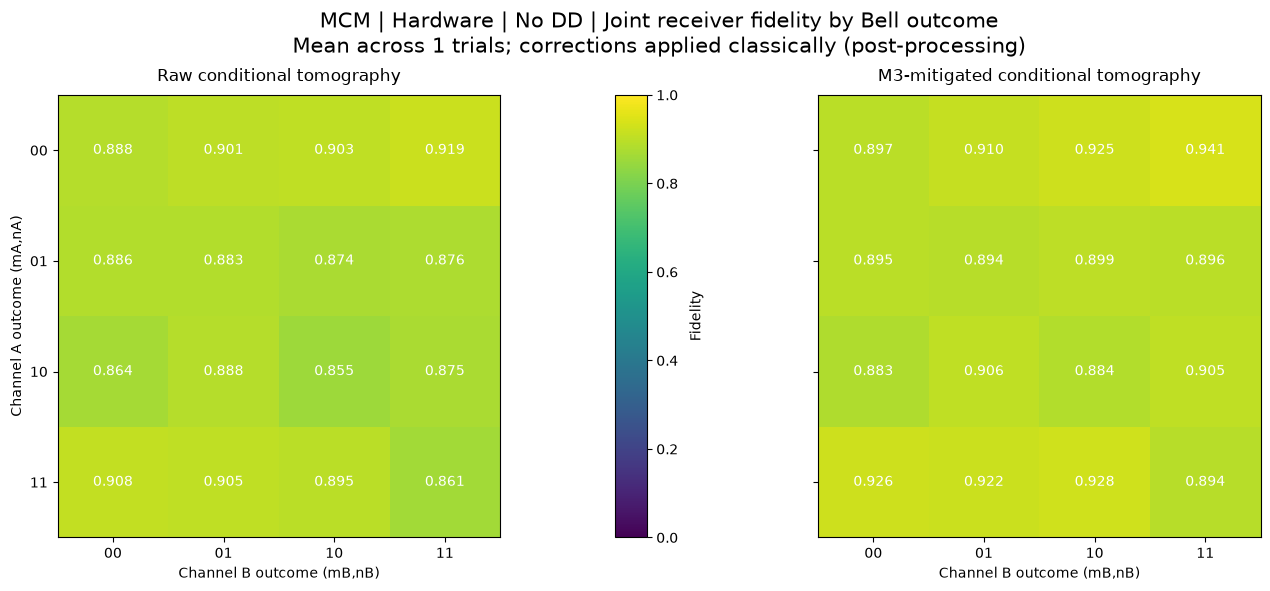

  Saved: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\rank1_bell_outcome_fidelity_no_dd_MCM_v044.png


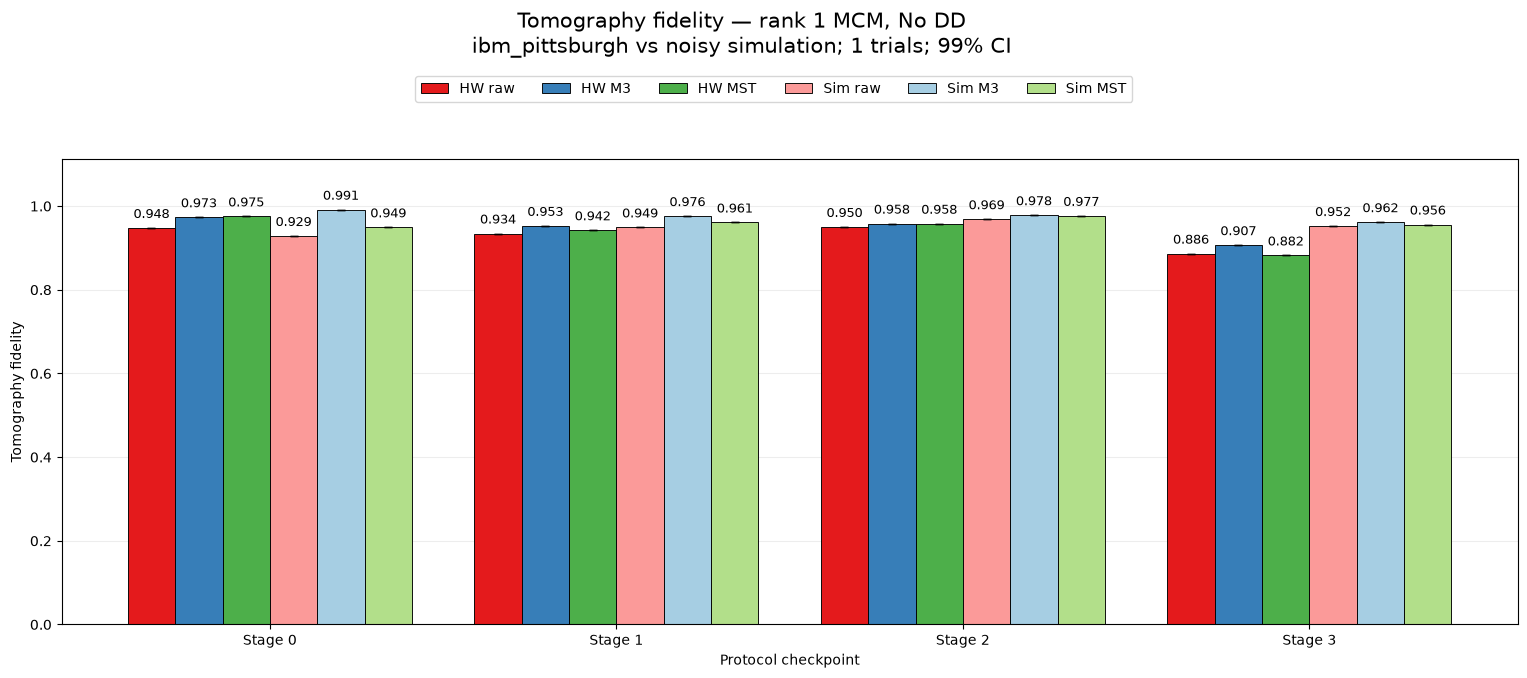

Saved C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\rank1_mcm_tomography_no_dd.png and matching CSV


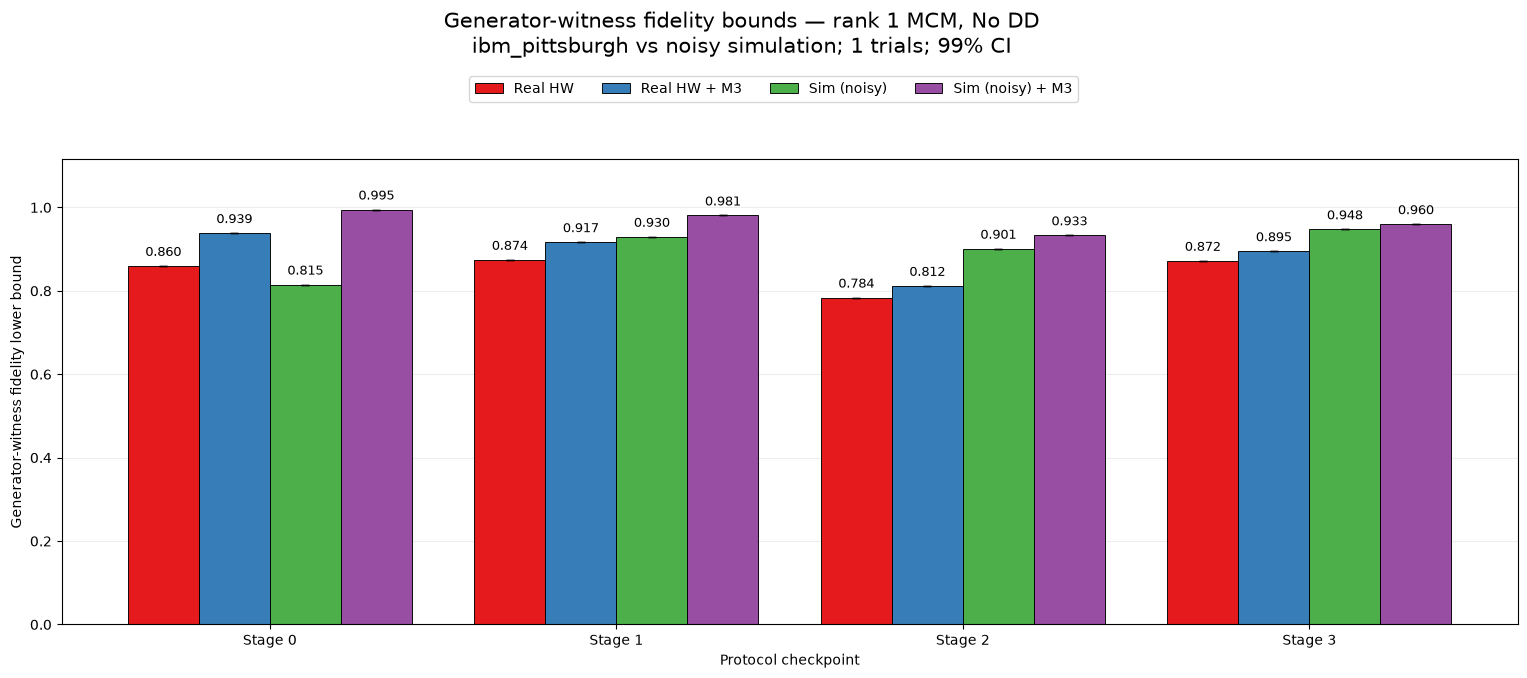

Saved C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\rank1_mcm_witness_no_dd.png and matching CSV
[19:54:30] MCM | DD=No DD | Stage 0 | SWAP
[MCM | DD=No DD | Stage 0 | SWAP] Full-stage scheduling: 1 circuits, DD=none, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\stage_schedule_9306e80386.json
[MCM | DD=No DD | Stage 0 | SWAP] Full-stage scheduling: 1 circuits, DD=none, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\stage_schedule_59c838e484.json
[MCM | DD=No DD | Stage 0 | SWAP] Full-stage s

base_primitive._run:WARNING:2026-09-12 19:55:10,375: Even though a session/batch context manager is open this job will run in job mode because the sampler primitive was initialized outside the context manager. Move the sampler initialization inside the context manager to run in a session/batch.


[MCM | DD=No DD | Stage 0 | SWAP | M3 calibration, attempt 1/5] accepted: job_id=df5365e4-ace5-44ee-b4eb-88df77040089
  job df5365e4-ace5-44ee-b4eb-88df77040089: JobStatus.RUNNING
  job df5365e4-ace5-44ee-b4eb-88df77040089: JobStatus.DONE
[MCM | DD=No DD | Stage 0 | SWAP | M3 calibration, attempt 1/5] result received
[MCM | DD=No DD | Stage 0 | SWAP] Noisy simulation SWAP trial 1/1, s0_swp_c -> physical [92]
[19:55:29] MCM | DD=No DD | Stage 0 (2-copy) | SWAP
[MCM | DD=No DD | Stage 0 (2-copy) | SWAP] Full-stage scheduling: 1 circuits, DD=none, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\stage_schedule_cc7b5129ea.json
[MCM | DD=No DD | Stage 0 (2-copy) | SWAP] Full-stage scheduling: 1 circuits, DD=none, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acc

base_primitive._run:WARNING:2026-09-12 19:56:09,023: Even though a session/batch context manager is open this job will run in job mode because the sampler primitive was initialized outside the context manager. Move the sampler initialization inside the context manager to run in a session/batch.


[MCM | DD=No DD | Stage 0 (2-copy) | SWAP | M3 calibration, attempt 1/5] accepted: job_id=d013ff3e-e08c-43d2-9172-62cab4d48828
  job d013ff3e-e08c-43d2-9172-62cab4d48828: JobStatus.RUNNING
  job d013ff3e-e08c-43d2-9172-62cab4d48828: JobStatus.DONE
[MCM | DD=No DD | Stage 0 (2-copy) | SWAP | M3 calibration, attempt 1/5] result received
[MCM | DD=No DD | Stage 0 (2-copy) | SWAP] Noisy simulation SWAP trial 1/1, s0_swp2_c -> physical [91]
[19:56:29] MCM | DD=No DD | Stage 1 | SWAP
[MCM | DD=No DD | Stage 1 | SWAP] Full-stage scheduling: 1 circuits, DD=none, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\stage_schedule_c66b76982a.json
[MCM | DD=No DD | Stage 1 | SWAP] Full-stage scheduling: 1 circuits, DD=none, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_ac

...

[MCM | DD=No DD | Stage 2 (2-copy) | SWAP | M3 calibration, attempt 1/5] accepted: job_id=11cf46af-db63-4a16-b27e-ad4856715e0e
  job 11cf46af-db63-4a16-b27e-ad4856715e0e: JobStatus.RUNNING
  job 11cf46af-db63-4a16-b27e-ad4856715e0e: JobStatus.DONE
[MCM | DD=No DD | Stage 2 (2-copy) | SWAP | M3 calibration, attempt 1/5] result received
[MCM | DD=No DD | Stage 2 (2-copy) | SWAP] Noisy simulation SWAP trial 1/1, rank1_stage2_swp2_c -> physical [91]
[20:01:12] MCM | DD=No DD | Stage 3 | SWAP
[MCM | DD=No DD | Stage 3 | SWAP] Full-stage scheduling: 1 circuits, DD=none, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\stage_schedule_2178f5c7c7.json
[MCM | DD=No DD | Stage 3 | SWAP] Full-stage scheduling: 1 circuits, DD=none, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm

base_primitive._run:WARNING:2026-09-12 20:01:49,965: Even though a session/batch context manager is open this job will run in job mode because the sampler primitive was initialized outside the context manager. Move the sampler initialization inside the context manager to run in a session/batch.


[MCM | DD=No DD | Stage 3 | SWAP | M3 calibration, attempt 1/5] accepted: job_id=88baae9f-0b4c-4cf1-9a9c-80e92a7f0f54
  job 88baae9f-0b4c-4cf1-9a9c-80e92a7f0f54: JobStatus.RUNNING
  job 88baae9f-0b4c-4cf1-9a9c-80e92a7f0f54: JobStatus.DONE
[MCM | DD=No DD | Stage 3 | SWAP | M3 calibration, attempt 1/5] result received
[MCM | DD=No DD | Stage 3 | SWAP] Noisy simulation SWAP trial 1/1, rank1_recv_swp_c -> physical [93]
[20:02:10] MCM | DD=No DD | Stage 3 (2-copy) | SWAP
[MCM | DD=No DD | Stage 3 (2-copy) | SWAP] Full-stage scheduling: 1 circuits, DD=none, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\stage_schedule_102d20d676.json
[MCM | DD=No DD | Stage 3 (2-copy) | SWAP] Full-stage scheduling: 1 circuits, DD=none, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs

base_primitive._run:WARNING:2026-09-12 20:02:49,608: Even though a session/batch context manager is open this job will run in job mode because the sampler primitive was initialized outside the context manager. Move the sampler initialization inside the context manager to run in a session/batch.


[MCM | DD=No DD | Stage 3 (2-copy) | SWAP | M3 calibration, attempt 1/5] accepted: job_id=b0bf57b4-ffc3-4f53-8b92-4035415f8f0b
  job b0bf57b4-ffc3-4f53-8b92-4035415f8f0b: JobStatus.RUNNING
  job b0bf57b4-ffc3-4f53-8b92-4035415f8f0b: JobStatus.DONE
[MCM | DD=No DD | Stage 3 (2-copy) | SWAP | M3 calibration, attempt 1/5] result received
[MCM | DD=No DD | Stage 3 (2-copy) | SWAP] Noisy simulation SWAP trial 1/1, recv_swp2_c -> physical [79]


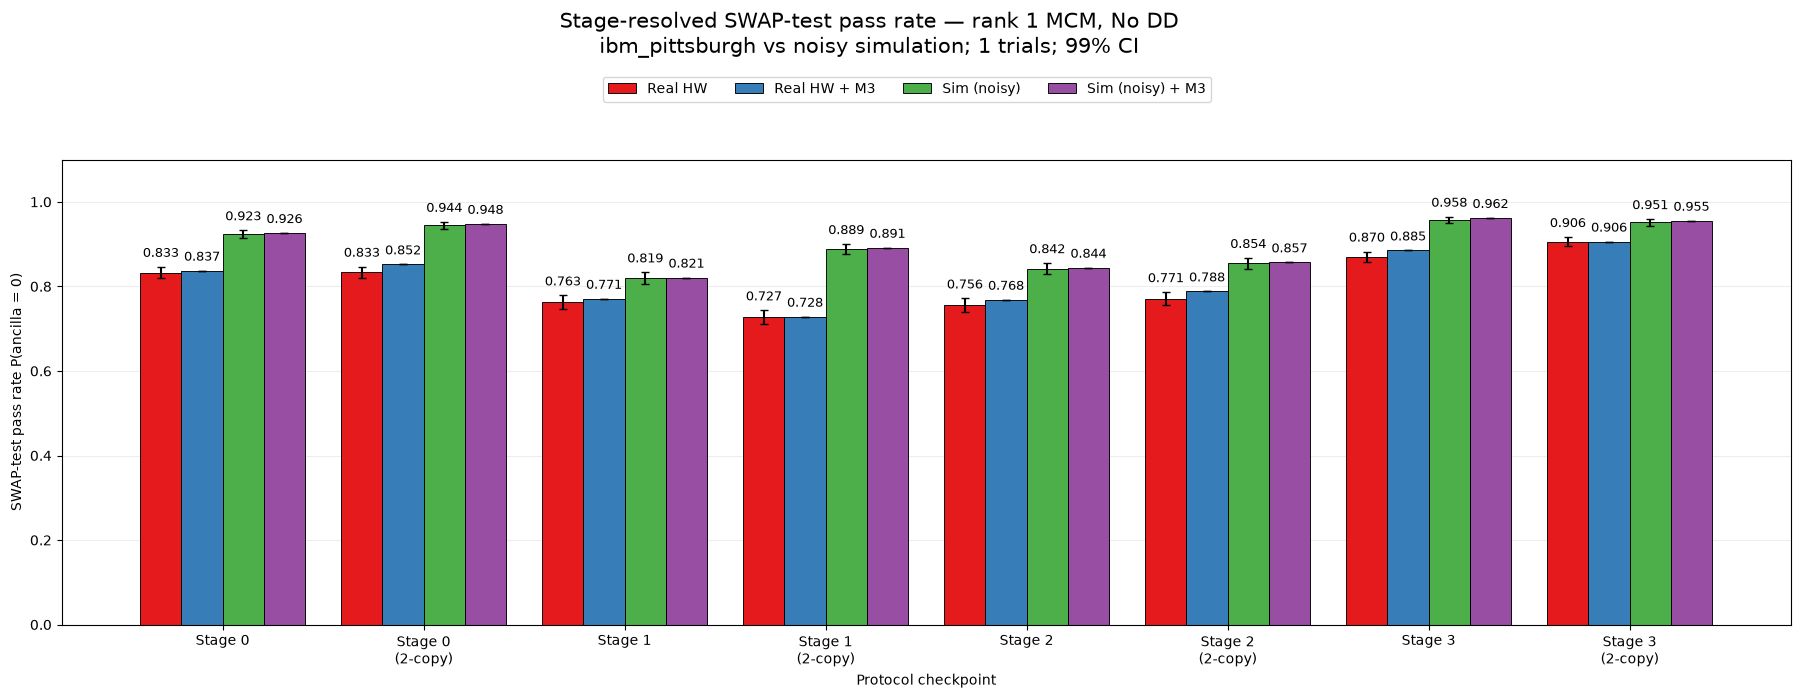

Saved C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\rank1_mcm_swap_passrate_no_dd.png and matching CSV
[20:03:11] MCM | DD=XY4 | Stage 0 | Hardware | trial 1/1 | tomography
[MCM | DD=XY4 | Stage 0 | Hardware | trial 1/1 | tomography] Full-stage scheduling: 1 circuits, DD=XY4, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\stage_schedule_e446e838f1.json
[MCM | DD=XY4 | Stage 0 | Hardware | trial 1/1 | tomography] Full-stage scheduling: 1 circuits, DD=none, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batc

base_primitive._run:WARNING:2026-09-12 20:06:19,976: Even though a session/batch context manager is open this job will run in job mode because the sampler primitive was initialized outside the context manager. Move the sampler initialization inside the context manager to run in a session/batch.


[MCM | DD=XY4 | Stage 0 | Noisy simulation | trial 1/1 | tomography | M3 calibration, attempt 1/5] accepted: job_id=007ccfc2-ed90-466d-8164-b868a014bacc
  job 007ccfc2-ed90-466d-8164-b868a014bacc: JobStatus.RUNNING
  job 007ccfc2-ed90-466d-8164-b868a014bacc: JobStatus.DONE
[MCM | DD=XY4 | Stage 0 | Noisy simulation | trial 1/1 | tomography | M3 calibration, attempt 1/5] result received
[MCM | DD=XY4 | Stage 0 | Noisy simulation | trial 1/1 | tomography | tomography raw/M3, attempt 1/5] submitting experiment...


base_primitive._run:WARNING:2026-09-12 20:06:36,509: Even though a session/batch context manager is open this job will run in job mode because the sampler primitive was initialized outside the context manager. Move the sampler initialization inside the context manager to run in a session/batch.


[MCM | DD=XY4 | Stage 0 | Noisy simulation | trial 1/1 | tomography | tomography raw/M3, attempt 1/5] job 0 accepted: job_id=b4f0c95d-5138-4d0b-bcf8-c44b4545ac1a
  job b4f0c95d-5138-4d0b-bcf8-c44b4545ac1a: JobStatus.RUNNING
  job b4f0c95d-5138-4d0b-bcf8-c44b4545ac1a: JobStatus.DONE
[MCM | DD=XY4 | Stage 0 | Noisy simulation | trial 1/1 | tomography | tomography raw/M3, attempt 1/5] experiment result received
[MCM | DD=XY4 | Stage 0 | Noisy simulation | trial 1/1 | tomography] All 9 raw tomography bases saved: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\tomo_raw_65bc2b6c84.json
[MCM | DD=XY4 | Stage 0 | Noisy simulation | trial 1/1 | tomography] M3 library processed 9 bases; max projection L1=0.000 (diagnostic only). Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\new

...

[MCM | DD=XY4 | Stage 3 | Noisy simulation | trial 1/1 | tomography | tomography raw/M3, attempt 1/5] job 0 accepted: job_id=9e2f9e54-105e-48c1-af23-21eb3b8773e0
  job 9e2f9e54-105e-48c1-af23-21eb3b8773e0: JobStatus.RUNNING
  job 9e2f9e54-105e-48c1-af23-21eb3b8773e0: JobStatus.DONE
[MCM | DD=XY4 | Stage 3 | Noisy simulation | trial 1/1 | tomography | tomography raw/M3, attempt 1/5] experiment result received
[MCM | DD=XY4 | Stage 3 | Noisy simulation | trial 1/1 | tomography] All 9 raw tomography bases saved: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\tomo_raw_ad36fafc18.json
[MCM | DD=XY4 | Stage 3 | Noisy simulation | trial 1/1 | tomography] M3 library processed 9 bases; max projection L1=0.000 (diagnostic only). Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\new

base_primitive._run:WARNING:2026-09-12 20:31:41,098: Even though a session/batch context manager is open this job will run in job mode because the sampler primitive was initialized outside the context manager. Move the sampler initialization inside the context manager to run in a session/batch.


[MCM | DD=XY4 | Stage 3 | Noisy simulation | trial 1/1 | tomography | mitigated tomography on aer_simulator_from(ibm_pittsburgh), attempt 1/5] job 0 accepted: job_id=433b6335-0351-42b9-87c0-ef239902dc7c
  job 433b6335-0351-42b9-87c0-ef239902dc7c: JobStatus.RUNNING
  job 433b6335-0351-42b9-87c0-ef239902dc7c: JobStatus.DONE
[MCM | DD=XY4 | Stage 3 | Noisy simulation | trial 1/1 | tomography | mitigated tomography on aer_simulator_from(ibm_pittsburgh), attempt 1/5] experiment result received
[20:31:57] MCM | DD=XY4 | Stage 3 | Noisy simulation | trial 1/1 | generator witness
[MCM | DD=XY4 | Stage 3 | Noisy simulation | trial 1/1 | generator witness] Full-stage scheduling: 1 circuits, DD=XY4, 8 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\stage_schedule_013ebc12f0.json
[MCM | DD=XY4 | Stage 3 | Noisy simulation | tria

base_primitive._run:WARNING:2026-09-12 20:31:58,246: Even though a session/batch context manager is open this job will run in job mode because the sampler primitive was initialized outside the context manager. Move the sampler initialization inside the context manager to run in a session/batch.


[MCM | DD=XY4 | Stage 3 | Noisy simulation | trial 1/1 | generator witness | Stage 3 physically corrected generator witness, attempt 1/5] accepted: job_id=d766643e-5bb1-4851-a181-3d6c2f300b0c
  job d766643e-5bb1-4851-a181-3d6c2f300b0c: JobStatus.RUNNING
  job d766643e-5bb1-4851-a181-3d6c2f300b0c: JobStatus.DONE
[MCM | DD=XY4 | Stage 3 | Noisy simulation | trial 1/1 | generator witness | Stage 3 physically corrected generator witness, attempt 1/5] result received
  Saved CSV: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\rank1_bell_outcome_fidelity_xy4_MCM_v044.csv


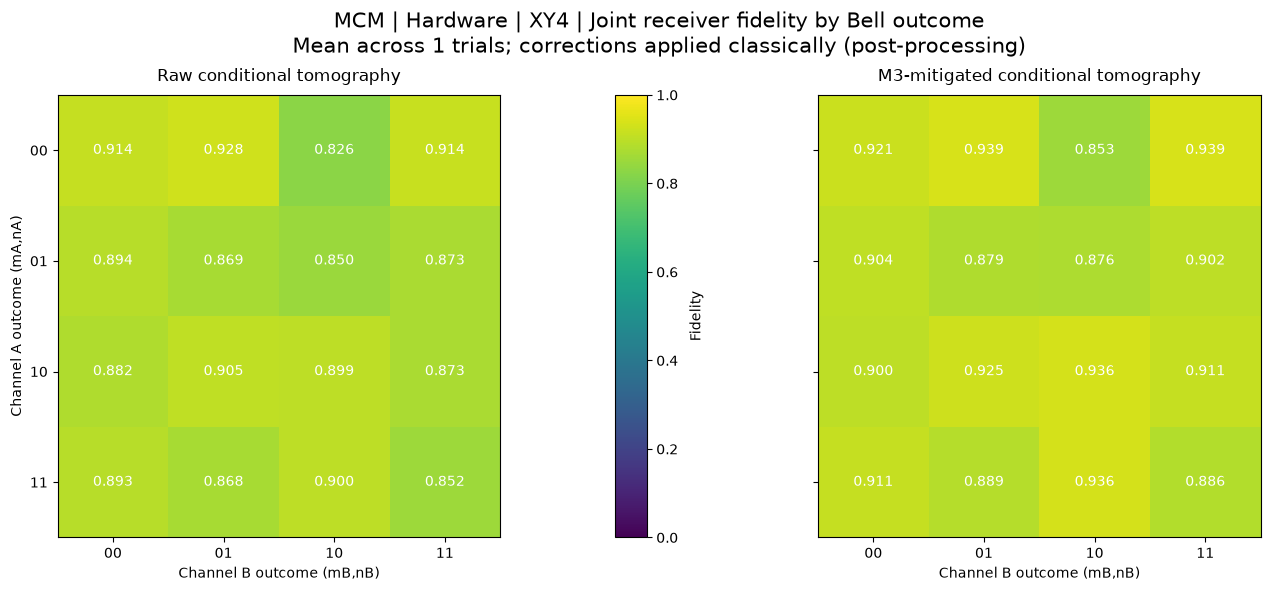

  Saved: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\rank1_bell_outcome_fidelity_xy4_MCM_v044.png


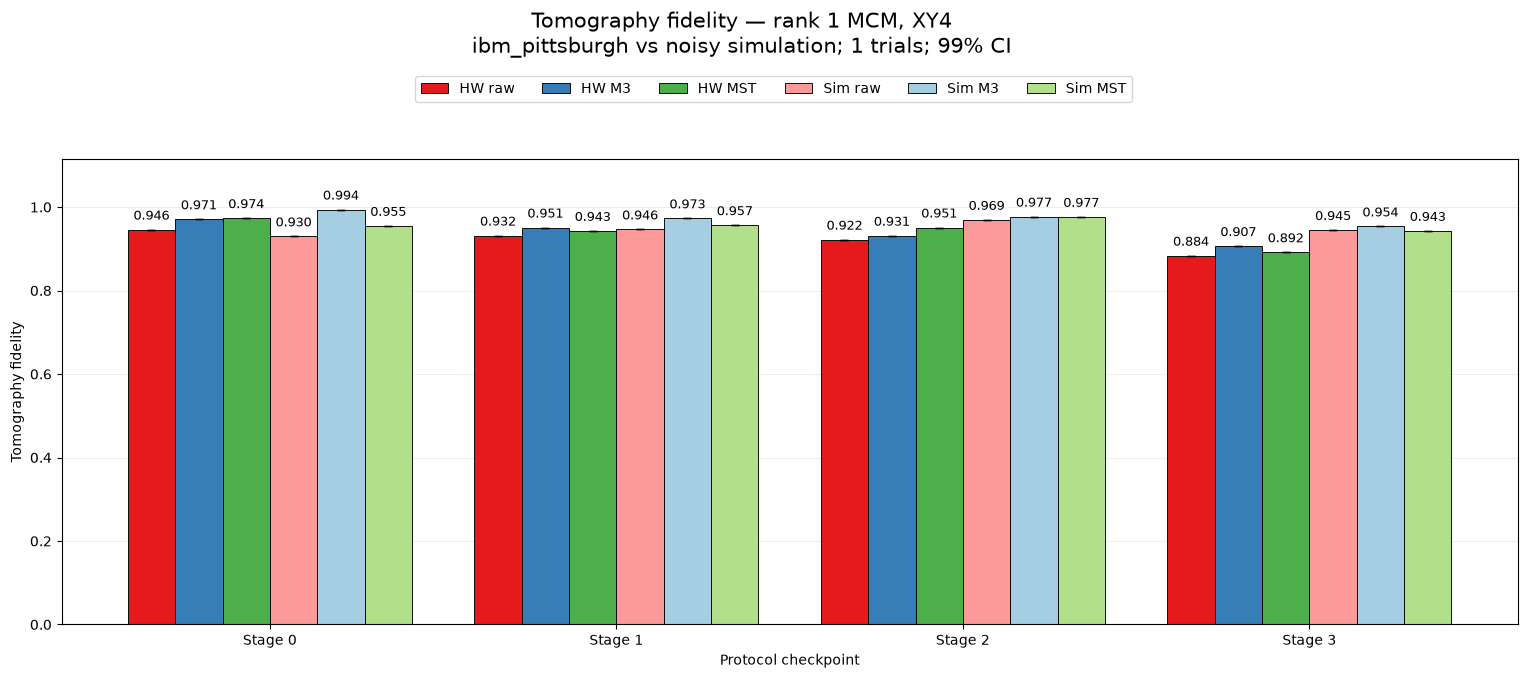

Saved C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\rank1_mcm_tomography_xy4.png and matching CSV


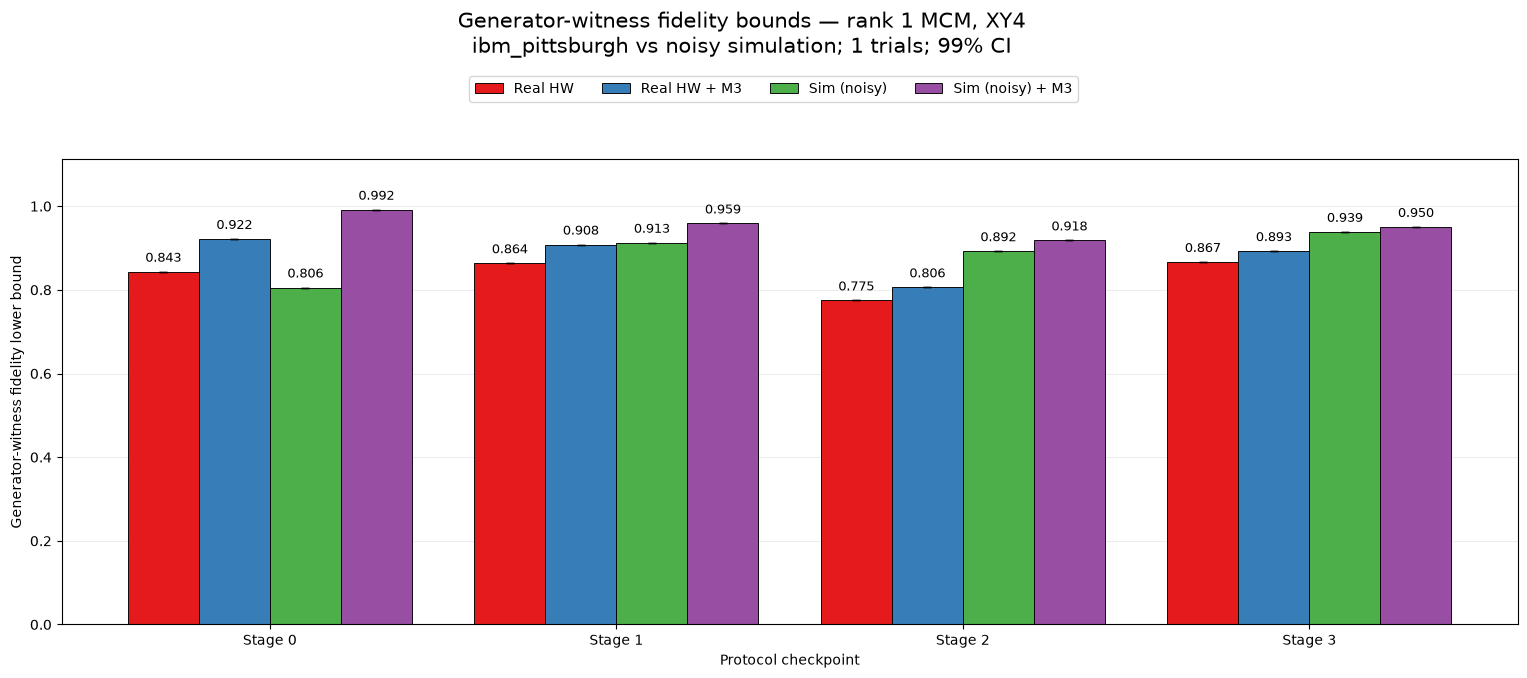

Saved C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\rank1_mcm_witness_xy4.png and matching CSV
[20:32:16] MCM | DD=XY4 | Stage 0 | SWAP
[MCM | DD=XY4 | Stage 0 | SWAP] Full-stage scheduling: 1 circuits, DD=XY4, 29 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\stage_schedule_258300d943.json
[MCM | DD=XY4 | Stage 0 | SWAP] Full-stage scheduling: 1 circuits, DD=none, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\stage_schedule_b20e5b88ae.json
[MCM | DD=XY4 | Stage 0 | SWAP] Full-stage scheduling:

base_primitive._run:WARNING:2026-09-12 20:32:56,293: Even though a session/batch context manager is open this job will run in job mode because the sampler primitive was initialized outside the context manager. Move the sampler initialization inside the context manager to run in a session/batch.


[MCM | DD=XY4 | Stage 0 | SWAP | M3 calibration, attempt 1/5] accepted: job_id=70e9599d-f9de-4754-8e73-5c1867d01c80
  job 70e9599d-f9de-4754-8e73-5c1867d01c80: JobStatus.RUNNING
  job 70e9599d-f9de-4754-8e73-5c1867d01c80: JobStatus.DONE
[MCM | DD=XY4 | Stage 0 | SWAP | M3 calibration, attempt 1/5] result received
[MCM | DD=XY4 | Stage 0 | SWAP] Noisy simulation SWAP trial 1/1, s0_swp_c -> physical [92]
[20:33:16] MCM | DD=XY4 | Stage 0 (2-copy) | SWAP
[MCM | DD=XY4 | Stage 0 (2-copy) | SWAP] Full-stage scheduling: 1 circuits, DD=XY4, 27 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\stage_schedule_af540f46f6.json
[MCM | DD=XY4 | Stage 0 (2-copy) | SWAP] Full-stage scheduling: 1 circuits, DD=none, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\n

base_primitive._run:WARNING:2026-09-12 20:33:55,481: Even though a session/batch context manager is open this job will run in job mode because the sampler primitive was initialized outside the context manager. Move the sampler initialization inside the context manager to run in a session/batch.


[MCM | DD=XY4 | Stage 0 (2-copy) | SWAP | M3 calibration, attempt 1/5] accepted: job_id=7b7ed9bc-d48c-4123-811c-a98569b17d33
  job 7b7ed9bc-d48c-4123-811c-a98569b17d33: JobStatus.RUNNING
  job 7b7ed9bc-d48c-4123-811c-a98569b17d33: JobStatus.DONE
[MCM | DD=XY4 | Stage 0 (2-copy) | SWAP | M3 calibration, attempt 1/5] result received
[MCM | DD=XY4 | Stage 0 (2-copy) | SWAP] Noisy simulation SWAP trial 1/1, s0_swp2_c -> physical [91]
[20:34:15] MCM | DD=XY4 | Stage 1 | SWAP
[MCM | DD=XY4 | Stage 1 | SWAP] Full-stage scheduling: 1 circuits, DD=XY4, 58 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\stage_schedule_76e42a4d25.json
[MCM | DD=XY4 | Stage 1 | SWAP] Full-stage scheduling: 1 circuits, DD=none, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\

...

[MCM | DD=XY4 | Stage 2 (2-copy) | SWAP | M3 calibration, attempt 1/5] accepted: job_id=b31f1478-e94b-4b03-b8cb-184e68153aee
  job b31f1478-e94b-4b03-b8cb-184e68153aee: JobStatus.RUNNING
  job b31f1478-e94b-4b03-b8cb-184e68153aee: JobStatus.DONE
[MCM | DD=XY4 | Stage 2 (2-copy) | SWAP | M3 calibration, attempt 1/5] result received
[MCM | DD=XY4 | Stage 2 (2-copy) | SWAP] Noisy simulation SWAP trial 1/1, rank1_stage2_swp2_c -> physical [91]
[20:39:25] MCM | DD=XY4 | Stage 3 | SWAP
[MCM | DD=XY4 | Stage 3 | SWAP] Full-stage scheduling: 1 circuits, DD=XY4, 20 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\stage_schedule_a2bdaa09f6.json
[MCM | DD=XY4 | Stage 3 | SWAP] Full-stage scheduling: 1 circuits, DD=none, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acch

base_primitive._run:WARNING:2026-09-12 20:40:05,725: Even though a session/batch context manager is open this job will run in job mode because the sampler primitive was initialized outside the context manager. Move the sampler initialization inside the context manager to run in a session/batch.


[MCM | DD=XY4 | Stage 3 | SWAP | M3 calibration, attempt 1/5] accepted: job_id=91e23ac7-13bf-4e98-8f87-e25d3f9c2f80
  job 91e23ac7-13bf-4e98-8f87-e25d3f9c2f80: JobStatus.RUNNING
  job 91e23ac7-13bf-4e98-8f87-e25d3f9c2f80: JobStatus.DONE
[MCM | DD=XY4 | Stage 3 | SWAP | M3 calibration, attempt 1/5] result received
[MCM | DD=XY4 | Stage 3 | SWAP] Noisy simulation SWAP trial 1/1, rank1_recv_swp_c -> physical [93]
[20:40:27] MCM | DD=XY4 | Stage 3 (2-copy) | SWAP
[MCM | DD=XY4 | Stage 3 (2-copy) | SWAP] Full-stage scheduling: 1 circuits, DD=XY4, 16 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\audits\stage_schedule_598d07474c.json
[MCM | DD=XY4 | Stage 3 (2-copy) | SWAP] Full-stage scheduling: 1 circuits, DD=none, 0 cycles. Audit: C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\

base_primitive._run:WARNING:2026-09-12 20:41:07,072: Even though a session/batch context manager is open this job will run in job mode because the sampler primitive was initialized outside the context manager. Move the sampler initialization inside the context manager to run in a session/batch.


[MCM | DD=XY4 | Stage 3 (2-copy) | SWAP | M3 calibration, attempt 1/5] accepted: job_id=79dd9f39-c92a-4b73-9e63-221c3f65999a
  job 79dd9f39-c92a-4b73-9e63-221c3f65999a: JobStatus.RUNNING
  job 79dd9f39-c92a-4b73-9e63-221c3f65999a: JobStatus.DONE
[MCM | DD=XY4 | Stage 3 (2-copy) | SWAP | M3 calibration, attempt 1/5] result received
[MCM | DD=XY4 | Stage 3 (2-copy) | SWAP] Noisy simulation SWAP trial 1/1, recv_swp2_c -> physical [79]


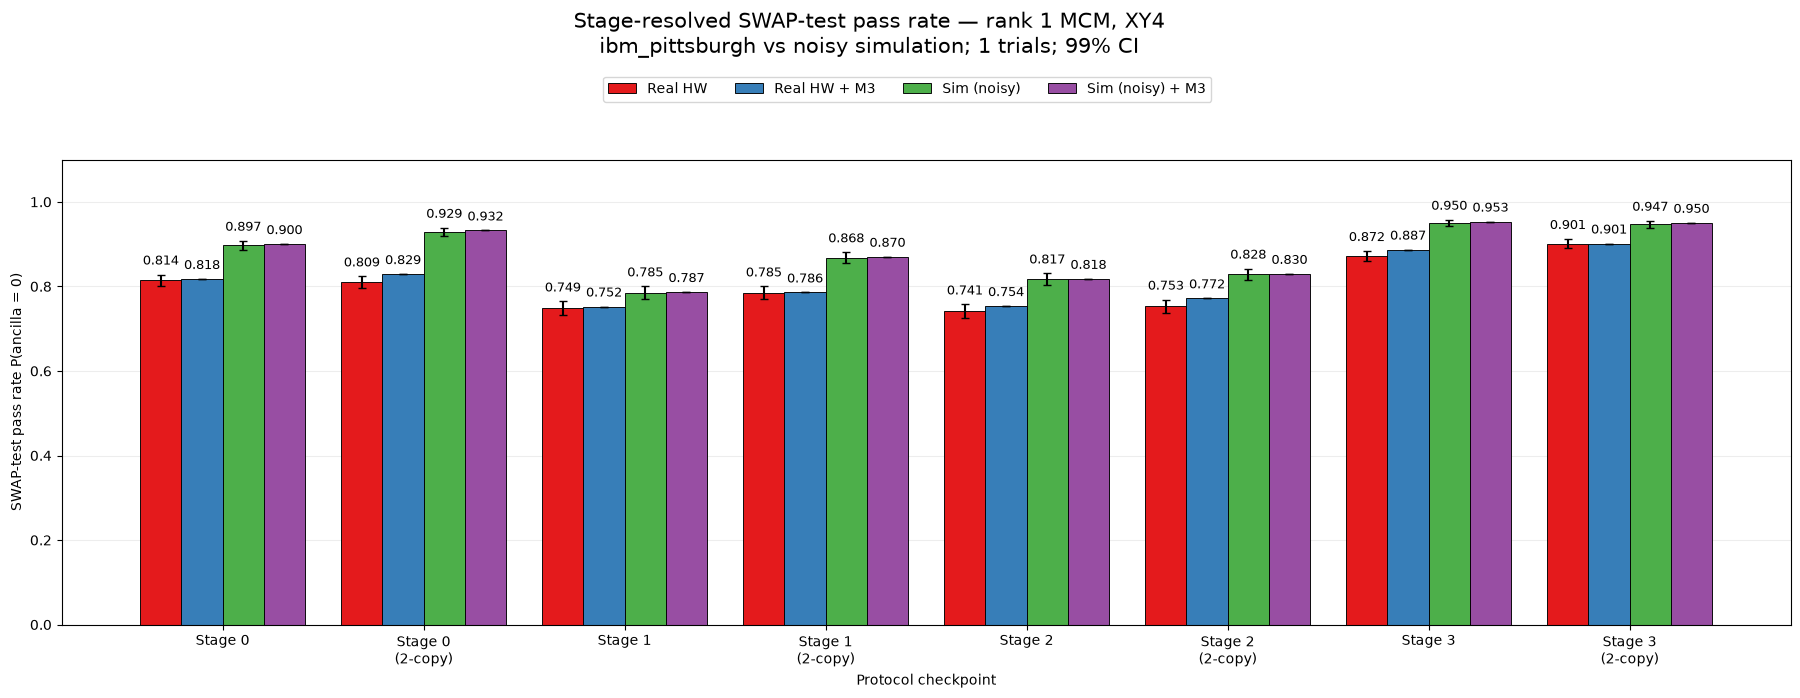

Saved C:\Users\limzh\Downloads\ame52_project\v4_2EPR\reduce_2qubit_gates_messy\test_mcm_vs_dcm_acchen\claude\newscripts\revised_notebooks\final_scripts\for_school_comp_lab\test\ame52_mcm_rank1_v044_batch\rank1_mcm_swap_passrate_xy4.png and matching CSV


In [9]:

RUN_EXPERIMENT = True
if RUN_EXPERIMENT:
    try:
        output_paths = run_all_policy_comparisons()
    finally:
        close_hardware_batches()
